# Evidence-Aware Classification of AI-Linked Workforce Events Using Machine Learning
## Part 1: Data Preparation and Exploratory Data Analysis

**Course:** Data Science Tools and Techniques (DSTT), MS Data Science
**Group members:** Ayesha Naeem (26L-8007) · Muhammad Mazhar (26L-8027)
**Dataset:** AI Layoffs Register (AI Layoffs Index, methodology v1.36, snapshot 2026-10-23)

This notebook covers everything from getting the dataset to exploratory data analysis (EDA), following Phases 1–2 of our approved proposal. **No models are trained here**; model training and evaluation are Part 2.

---

### Table of contents
1. [Title and table of contents](#Evidence-Aware-Classification-of-AI-Linked-Workforce-Events-Using-Machine-Learning)
2. [Introduction and objectives](#2.-Introduction-and-objectives)
3. [Environment setup](#3.-Environment-setup)
4. [Dataset loading and description](#4.-Dataset-loading-and-description)
5. [Data cleaning](#5.-Data-cleaning)
   - 5.1 Column names, whitespace and categories · 5.2 Type conversion · 5.3 Missing values · 5.4 Duplicates and related records · 5.5 Harmonising Country and Sector · 5.6 Outliers
6. [Preprocessing and transformations](#6.-Preprocessing-and-transformations)
   - 6.1 Text cleaning and company masking · 6.2 Date features · 6.3 Parsing "% of workforce" · 6.4 Job families · 6.5 Leakage audit · 6.6 Group-aware train/test split · 6.7 Preprocessing pipeline
7. [Feature engineering and selection](#7.-Feature-engineering-and-selection)
8. [Exploratory data analysis](#8.-Exploratory-data-analysis)
9. [Key observations and insights](#9.-Key-observations-and-insights)
10. [Save outputs](#10.-Save-outputs)

## 2. Introduction and objectives

Employers often give AI as one reason for layoffs and workforce restructuring, but how strongly they tie the cut to AI varies a lot. The **AI Layoffs Register** records each AI-linked workforce event together with an **`Attribution`** label that says how the AI link was established:

| Label | Meaning (from the register's methodology) |
|---|---|
| **explicit** | The employer itself declared the cut AI-related. |
| **mixed** | The employer cited AI *among other reasons* (cost, restructuring, efficiency, …). |
| **blamed** | The employer named no AI reason; the press, unions or analysts linked it to AI. |

The full project builds a multi-class classifier that predicts `Attribution` from the event's **text** (claim and source title) and its **context** (sector, country, event kind, execution status, date, headcount).

**Research questions**
- **RQ1:** Which textual and contextual features are most informative for separating explicit, mixed and blamed events?
- **RQ2:** Does combining text with contextual metadata beat text alone?
- **RQ3:** How do traditional classifiers compare with ensemble methods? *(Part 2 only.)*

**Objectives of Part 1**
1. Load and verify the fixed 320-row snapshot.
2. Clean the data, handle missing values, duplicates, messy categories and outliers without dropping rows.
3. Audit every column for **target leakage** and exclude the leaking ones.
4. Create a **group-aware** train/test split (no company in both sets) *before* any fitting.
5. Engineer text and context features, build a train-only preprocessing pipeline, and rank features.
6. Explore the data visually (12+ figures) and summarise what it implies for modelling.

> **Caveat.** The `Attribution` label is the register's documented *classification of what was said* about each event. It is **not** proof that AI caused any job losses, and neither is anything a model learns from it. This project asks whether the register's categories can be reproduced from the available evidence, not whether AI destroyed jobs.

## 3. Environment setup

Imports, a fixed random seed, relative paths, and one plotting style for all figures. Each class has a fixed colour from a colour-blind-safe palette (blue / orange / aqua, validated for colour-vision deficiency). The `savefig` helper saves every figure as a PNG to `figures/`.

In [1]:
# --- Standard library ---
import json
import re
import urllib.request
from pathlib import Path

# --- Third-party ---
import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from IPython.display import display
from scipy.stats import chi2_contingency, kruskal
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import chi2, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- Reproducibility ---
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Relative paths (run the notebook from the project root) ---
DATA_RAW = Path("data") / "raw"
DATA_PROCESSED = Path("data") / "processed"
FIG_DIR = Path("figures")
for folder in (DATA_RAW, DATA_PROCESSED, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RAW_CSV = DATA_RAW / "ai-layoffs-register.csv"
MIRROR_URL = ("https://raw.githubusercontent.com/adrianobuilder/demissoes_ia/"
              "main/raw/ai-layoffs-register.csv")

# --- Display options ---
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

# --- One consistent plotting style ---
CLASSES = ["explicit", "mixed", "blamed"]            # ordered by strength of employer attribution
CLASS_COLORS = {"explicit": "#2a78d6",               # blue
                "mixed": "#eb6834",                  # orange
                "blamed": "#1baf7a"}                 # aqua  (CVD-validated trio)
CLASS_PALETTE = [CLASS_COLORS[c] for c in CLASSES]
NEUTRAL, ACCENT = "#8a8983", "#6250d6"                # non-class series (grey, violet)
SURFACE, TEXT, TEXT2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SEQ_CMAP = "Blues"                                   # single-hue sequential map for heatmaps

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "legend.frameon": False, "text.color": TEXT, "axes.labelcolor": TEXT2,
    "xtick.color": TEXT2, "ytick.color": TEXT2, "figure.dpi": 100,
})

FIGURES_SAVED = []


def savefig(fig, name):
    """Save a figure as figures/<name>.png, show it inline, then close it."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    FIGURES_SAVED.append(path.name)
    plt.show()
    plt.close(fig)


def stacked_class_bars(ct, ax, horizontal=True, normalize=False):
    """Draw a class-stacked bar chart from a crosstab (rows = groups, columns = classes)."""
    data = ct.reindex(columns=CLASSES, fill_value=0)
    if normalize:
        data = data.div(data.sum(axis=1), axis=0)
    data.plot(kind="barh" if horizontal else "bar", stacked=True, ax=ax,
              color=CLASS_PALETTE, edgecolor=SURFACE, linewidth=1.5, width=0.75)
    ax.legend(title="Attribution", loc="best")
    return ax


print(f"python libs -> pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}, "
      f"scipy {scipy.__version__}, matplotlib {matplotlib.__version__}, seaborn {sns.__version__}")

python libs -> pandas 2.3.3, numpy 2.2.6, scikit-learn 1.7.2, scipy 1.15.3, matplotlib 3.10.9, seaborn 0.13.2


## 4. Dataset loading and description

**Source.** *AI Layoffs Register*, published by **AI Layoffs Index** ([ailayoffs.org](https://ailayoffs.org), methodology at [ailayoffs.org/methodology](https://ailayoffs.org/methodology)), also on [Kaggle](https://www.kaggle.com/datasets/ailayoffs/ai-layoffs-register-2023-2026-every-row-sourced). We use the **fixed snapshot of 2026-10-23 (methodology v1.36)** through a raw-CSV mirror. We do **not** use the live API endpoint, because it keeps growing and would break reproducibility.

The notebook reads `data/raw/ai-layoffs-register.csv` and downloads it from the mirror only if the file is missing. The file starts with a UTF-8 byte-order mark, so we read it with `encoding="utf-8-sig"`.

In [2]:
# Load the local copy; download the fixed snapshot from the mirror only if it is missing
if not RAW_CSV.exists():
    print(f"{RAW_CSV} not found, downloading from mirror ...")
    urllib.request.urlretrieve(MIRROR_URL, RAW_CSV)

raw = pd.read_csv(RAW_CSV, encoding="utf-8-sig")
print("Shape:", raw.shape)
raw.head(3)

Shape: (320, 20)


,Company,Date,Sector,Country,Functions,Roles counted,Roles reported (not counted),Why not counted,% of workforce,Evidence tier,Attribution,Execution,Counts in US index,Claim,Source,Source URL,Event ID,Kind,What the employer said,Job families
0,Barclays,2026-10-22,Banking,United Kingdom,"Support functions, including software developers: about 60% of the reductions from the...",5000.0,NaN,NaN,"about 5% of employees (Barclays' own figure; the Guardian puts the global staff at 93,...",Tier 1,mixed,partial,no,"Barclays' Q3 2026 results presentation (22 October 2026), 'Outcomes of SCA spend' (the...",Barclays: Q3 2026 Results Presentation,https://home.barclays/content/dam/home-barclays/documents/investor-relations/ResultAnn...,barclays-2026-10,cut,Cited AI among other reasons,Corporate functions; Software engineering and IT
1,National Australia Bank,2026-10-20,Banking,Australia,"Corporate functions (per NAB); Senior management positions (per NAB); Strategy, transf...",NaN,2500.0,"The company said the cut was not caused by AI; the company gave only an upper limit (""...",up to about 6% of its internal workforce (NAB),Tier 1,blamed,announced,no,"The Nightly (October 20, 2026): ""Kyle Rodda, a senior financial market analyst with Ca...",NAB (ASX announcement): NAB simplifying operating model and improving alignment to cus...,https://www.nab.com.au/news/nab-updates/nab-simplifying-operating-model-and-alignment-...,national-australia-bank-2026-10,cut,Denied the AI link others made,Corporate functions; Management layers; Operations and back office
2,Vermont Information Processing,2026-10-20,Beverage industry software,United States,Not specified,NaN,NaN,NaN,NaN,Tier 2,blamed,executed,no,"Seven Days (October 20, 2026): ""The move appears to be a real-world example of the pot...","Seven Days: A Colchester Tech Firm Has Been Leaning Into AI. On Tuesday, It Announced ...",https://www.sevendaysvt.com/news/a-colchester-tech-firm-has-been-leaning-into-ai-on-tu...,vermont-information-processing-2026-10,cut,Named no AI reason; others linked it to AI,Not specified


### 4.1 Headline facts and verification
We check the snapshot against the expected figures. Note: the proposal mentions "~228 companies"; **228 is actually the number of distinct `Sector` values**, and the dataset has **257 distinct companies**. The assertions below confirm this.

In [3]:
# Headline facts, asserted against the published snapshot description
dates_raw = pd.to_datetime(raw["Date"], format="%Y-%m-%d")
facts = {
    "rows": raw.shape[0],
    "columns": raw.shape[1],
    "first event date": dates_raw.min().date(),
    "last event date": dates_raw.max().date(),
    "distinct companies": raw["Company"].nunique(),
    "distinct Sector values": raw["Sector"].nunique(),
    "distinct Country values": raw["Country"].nunique(),
    "distinct Event IDs": raw["Event ID"].nunique(),
}
class_counts_raw = raw["Attribution"].value_counts()

assert raw.shape == (320, 20)
assert str(facts["first event date"]) == "2023-02-22" and str(facts["last event date"]) == "2026-10-22"
assert facts["distinct companies"] == 257 and facts["distinct Sector values"] == 228
assert class_counts_raw.to_dict() == {"mixed": 199, "blamed": 82, "explicit": 39}

display(pd.Series(facts, name="value").to_frame())
display(class_counts_raw.rename("events").to_frame())

,value
rows,320
columns,20
first event date,2023-02-22
last event date,2026-10-22
distinct companies,257
distinct Sector values,228
distinct Country values,50
distinct Event IDs,320


,events
Attribution,
mixed,199
blamed,82
explicit,39


### 4.2 Data dictionary
Each column is assigned a **role**: `input` (a candidate model feature), `target`, `leakage-excluded` (encodes the label or comes from the register's own assessment; kept for EDA only, see §6.5), `identifier` (used for grouping/deduplication, never as a feature), or `descriptive` (free text kept for context but not modelled in Part 1).

In [4]:
# Data dictionary: description and modelling role of every raw column
DICTIONARY = [
    ("Company", "Employer name", "identifier (group key for the split; masked in text)"),
    ("Date", "Date of the announcement / report (YYYY-MM-DD)", "input (date features)"),
    ("Sector", "Free-text industry description (228 distinct values)", "input (harmonised to sector_group)"),
    ("Country", "Free-text country / HQ description (50 distinct values)", "input (harmonised to country_primary, region, multi_country)"),
    ("Functions", "Free-text description of affected functions", "descriptive (structured version is Job families)"),
    ("Roles counted", "Headcount the register counts towards its AI index", "input (merged into headcount)"),
    ("Roles reported (not counted)", "Headcount reported but not counted by the register", "input (merged into headcount)"),
    ("Why not counted", "Register's reason for not counting the headcount", "leakage-excluded"),
    ("% of workforce", "Free-text share of workforce affected", "input (parsed to pct_workforce)"),
    ("Evidence tier", "Register's evidence-quality tier (Tier 1–3)", "leakage-excluded (EDA only)"),
    ("Attribution", "How the AI link was established: explicit / mixed / blamed", "target"),
    ("Execution", "Status of the cut: announced / executed / partial / reversed / unknown", "input"),
    ("Counts in US index", "Whether the event counts in the register's US index", "leakage-excluded (post-assessment)"),
    ("Claim", "Register's summary of the evidence, with quotations", "input (text)"),
    ("Source", "Title of the cited source, usually 'Publisher: headline'", "input (text, as source_title)"),
    ("Source URL", "URL of the cited source", "identifier (duplicate checks only)"),
    ("Event ID", "Unique event slug", "identifier"),
    ("Kind", "Event type: cut / workforce statement", "input"),
    ("What the employer said", "Register's summary of the employer's stance", "leakage-excluded (near one-to-one with label)"),
    ("Job families", "Semicolon-separated affected job families", "input (multi-hot encoded)"),
]
data_dictionary = pd.DataFrame(DICTIONARY, columns=["column", "description", "role"])
data_dictionary.insert(1, "dtype (raw)", data_dictionary["column"].map(raw.dtypes.astype(str)))
assert set(data_dictionary["column"]) == set(raw.columns)
data_dictionary

,column,dtype (raw),description,role
0,Company,object,Employer name,identifier (group key for the split; masked in text)
1,Date,object,Date of the announcement / report (YYYY-MM-DD),input (date features)
2,Sector,object,Free-text industry description (228 distinct values),input (harmonised to sector_group)
3,Country,object,Free-text country / HQ description (50 distinct values),"input (harmonised to country_primary, region, multi_country)"
4,Functions,object,Free-text description of affected functions,descriptive (structured version is Job families)
5,Roles counted,float64,Headcount the register counts towards its AI index,input (merged into headcount)
6,Roles reported (not counted),float64,Headcount reported but not counted by the register,input (merged into headcount)
7,Why not counted,object,Register's reason for not counting the headcount,leakage-excluded
8,% of workforce,object,Free-text share of workforce affected,input (parsed to pct_workforce)
9,Evidence tier,object,Register's evidence-quality tier (Tier 1–3),leakage-excluded (EDA only)


### 4.3 Overview table
Data type, missing count and %, number of unique values, and an example value for every column.

In [5]:
def overview(frame):
    """One row per column: dtype, missing, % missing, unique values and an example value."""
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing %": (frame.isna().mean() * 100).round(1),
        "unique": frame.nunique(),
        "example": [str(frame[c].dropna().iloc[0])[:70] for c in frame.columns],
    })

overview(raw)

,dtype,missing,missing %,unique,example
Company,object,0,0.0,257,Barclays
Date,object,0,0.0,239,2026-10-22
Sector,object,0,0.0,228,Banking
Country,object,0,0.0,50,United Kingdom
Functions,object,0,0.0,272,"Support functions, including software developers: about 60% of the red"
Roles counted,float64,227,70.9,75,5000.0
Roles reported (not counted),float64,156,48.8,93,2500.0
Why not counted,object,156,48.8,32,The company said the cut was not caused by AI; the company gave only a
% of workforce,object,105,32.8,204,about 5% of employees (Barclays' own figure; the Guardian puts the glo
Evidence tier,object,0,0.0,3,Tier 1


In [6]:
# Summary statistics for all columns (numeric and text)
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Company,320,257,Amazon,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,320,239,2026-05-07,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sector,320,228,Banking,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,320,50,United States,143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Functions,320,272,Not specified,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Roles counted,93.0,NaN,NaN,NaN,901.580645,1510.288321,3.0,150.0,314.0,950.0,8000.0
Roles reported (not counted),164.0,NaN,NaN,NaN,1743.713415,3432.122495,4.0,89.75,250.0,1204.25,21000.0
Why not counted,164,32,"The number was reported by the press, not stated publicly by the company.",45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
% of workforce,215,204,20%,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Evidence tier,320,3,Tier 2,149,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**What we see.** The data has 320 events and 20 columns: two numeric headcount columns and 18 text columns. Several columns are long free text (`Claim`, `Functions`, `% of workforce`, `Why not counted`), and `Sector`/`Country` are free-text "categories" with very high cardinality. Missing values are concentrated in the headcount columns, `Why not counted` and `% of workforce`. Section 5.3 shows that this missingness is **structural**, not random.

## 5. Data cleaning
Guiding rule: **no row is dropped**. With 320 events and only 39 `explicit` cases, every record matters. Problems are fixed by recoding, flagging or imputing (inside the train-only pipeline), never by deletion.

### 5.1 Column names, whitespace and categories
- Column names → `snake_case` (`% of workforce` → `pct_of_workforce`, `Source` → `source_title`).
- All text cells: collapse repeated whitespace and strip leading/trailing spaces.
- Low-cardinality categorical columns → lower case so that spelling variants cannot form separate levels.

In [7]:
def to_snake(col):
    """Convert a raw column name to snake_case."""
    if col.strip() == "% of workforce":
        return "pct_of_workforce"
    return re.sub(r"[^0-9a-z]+", "_", col.lower()).strip("_")

df = raw.copy()
df.columns = [to_snake(c) for c in df.columns]
df = df.rename(columns={"source": "source_title"})

# Whitespace cleanup on every text column; count how many cells actually change
NUMERIC_RAW = ["roles_counted", "roles_reported_not_counted"]
TEXT_RAW = [c for c in df.columns if c not in NUMERIC_RAW]
changed = 0
for c in TEXT_RAW:
    cleaned = df[c].str.replace(r"\s+", " ", regex=True).str.strip()
    changed += int((cleaned.fillna("") != df[c].fillna("")).sum())
    df[c] = cleaned

# Lower-case the categorical columns
CATEGORICAL_LOWER = ["attribution", "execution", "kind", "evidence_tier", "counts_in_us_index"]
for c in CATEGORICAL_LOWER:
    df[c] = df[c].str.lower()

print("Cells changed by whitespace cleanup:", changed)
print("Columns:", list(df.columns))
for c in CATEGORICAL_LOWER:
    print(f"  {c}: {sorted(df[c].unique())}")

Cells changed by whitespace cleanup:

 0
Columns: ['company', 'date', 'sector', 'country', 'functions', 'roles_counted', 'roles_reported_not_counted', 'why_not_counted', 'pct_of_workforce', 'evidence_tier', 'attribution', 'execution', 'counts_in_us_index', 'claim', 'source_title', 'source_url', 'event_id', 'kind', 'what_the_employer_said', 'job_families']
  attribution: ['blamed', 'explicit', 'mixed']
  execution: ['announced', 'executed', 'partial', 'reversed', 'unknown']
  kind: ['cut', 'workforce statement']
  evidence_tier: ['tier 1', 'tier 2', 'tier 3']
  counts_in_us_index: ['no', 'yes']


### 5.2 Type conversion
- `date` → `datetime64` (ISO format, so strict parsing is used).
- Headcount columns → numeric.
- **`headcount`**: the register stores a number *either* in `roles_counted` (the register counts it) *or* in `roles_reported_not_counted` (it does not). Section 6.5 shows that *which* column is filled leaks the label, so we merge them into one `headcount` column. We first assert that no row has both.

In [8]:
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d")
for c in NUMERIC_RAW:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# The two headcount columns are mutually exclusive, so merging them loses nothing
both_filled = df["roles_counted"].notna() & df["roles_reported_not_counted"].notna()
assert not both_filled.any(), "a row has both headcount columns filled"
df["headcount"] = df["roles_counted"].fillna(df["roles_reported_not_counted"])

print(df[["date", "roles_counted", "roles_reported_not_counted", "headcount"]].dtypes)
print("Rows with a headcount:", int(df["headcount"].notna().sum()), "/", len(df))

date                          datetime64[ns]
roles_counted                        float64
roles_reported_not_counted           float64
headcount                            float64
dtype: object
Rows with a headcount: 257 / 320


### 5.3 Missing values (NaN and hidden placeholders)
Missingness can hide as text: `Functions` and `Job families` use strings such as *"Not specified"* / *"Not disclosed"*, and `Execution` has an *"unknown"* level. We count both real `NaN`s and these placeholders.

In [9]:
# A cell is a placeholder if its whole content is one of these "no information" phrases
PLACEHOLDER_RE = r"^(?:not (?:specified|disclosed)(?: by the company)?|unknown|n/?a|none)\.?$"

nan_counts = df.isna().sum()
placeholder_counts = pd.Series(
    {c: int(df[c].fillna("").str.strip().str.contains(PLACEHOLDER_RE, case=False, regex=True).sum())
     if c in TEXT_RAW and c != "date" else 0 for c in df.columns})
missing_tbl = pd.DataFrame({"NaN": nan_counts, "placeholder": placeholder_counts})
missing_tbl["total"] = missing_tbl.sum(axis=1)
missing_tbl["total %"] = (missing_tbl["total"] / len(df) * 100).round(1)
missing_tbl = missing_tbl[missing_tbl["total"] > 0].sort_values("total", ascending=False)
display(missing_tbl)

# Which placeholder strings occur, and where
for c in ["functions", "job_families", "execution"]:
    hits = df.loc[df[c].str.contains(PLACEHOLDER_RE, case=False, regex=True), c]
    print(f"{c}: {hits.value_counts().to_dict()}")

,NaN,placeholder,total,total %
roles_counted,227,0,227,70.9
roles_reported_not_counted,156,0,156,48.8
why_not_counted,156,0,156,48.8
job_families,0,119,119,37.2
pct_of_workforce,105,0,105,32.8
headcount,63,0,63,19.7
functions,0,38,38,11.9
execution,0,4,4,1.2


functions: {'Not specified': 17, 'Not disclosed': 15, 'not specified by the company': 4, 'not disclosed': 2}
job_families: {'Not specified': 119}
execution: {'unknown': 4}


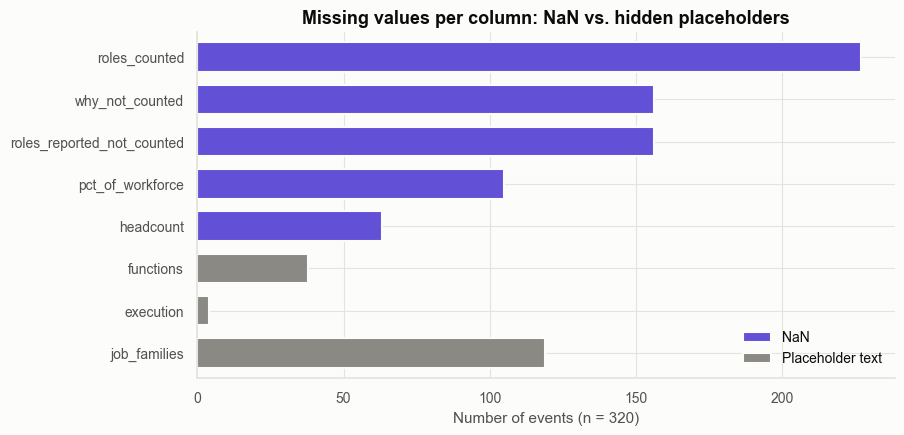

In [10]:
# Figure: missing and placeholder values per column
plot_tbl = missing_tbl.drop(columns=["total", "total %"]).sort_values("NaN")
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_tbl.plot(kind="barh", stacked=True, ax=ax, color=[ACCENT, NEUTRAL],
              edgecolor=SURFACE, linewidth=1.5, width=0.7)
ax.set_title("Missing values per column: NaN vs. hidden placeholders")
ax.set_xlabel(f"Number of events (n = {len(df)})")
ax.set_ylabel("")
ax.legend(["NaN", "Placeholder text"], loc="lower right")
savefig(fig, "fig01_missing_values")

Missingness rate **per class** for each incomplete column. If missingness were random, the rates would be similar across classes.

attribution,explicit,mixed,blamed
roles_counted is NaN,66.7,59.8,100.0
roles_reported_not_counted is NaN,74.4,56.8,17.1
why_not_counted is NaN,74.4,56.8,17.1
headcount (merged) is NaN,41.0,16.6,17.1
pct_of_workforce is NaN,38.5,24.6,50.0
job_families placeholder,46.2,43.7,17.1
functions placeholder,17.9,13.1,6.1
execution unknown,0.0,1.0,2.4


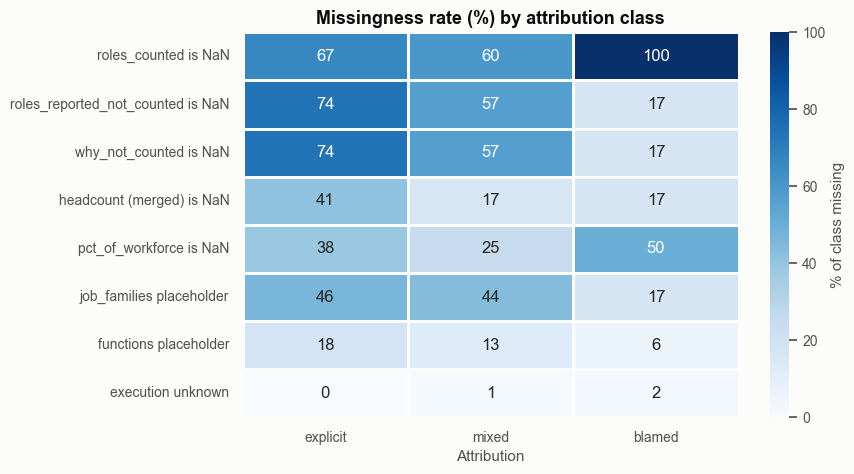

In [11]:
# Missingness indicators, then the rate per class
miss_ind = pd.DataFrame({
    "roles_counted is NaN": df["roles_counted"].isna(),
    "roles_reported_not_counted is NaN": df["roles_reported_not_counted"].isna(),
    "why_not_counted is NaN": df["why_not_counted"].isna(),
    "headcount (merged) is NaN": df["headcount"].isna(),
    "pct_of_workforce is NaN": df["pct_of_workforce"].isna(),
    "job_families placeholder": df["job_families"].str.contains(PLACEHOLDER_RE, case=False, regex=True),
    "functions placeholder": df["functions"].str.contains(PLACEHOLDER_RE, case=False, regex=True),
    "execution unknown": df["execution"].eq("unknown"),
})
miss_by_class = miss_ind.groupby(df["attribution"]).mean().T[CLASSES]
display((miss_by_class * 100).round(1))

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(miss_by_class * 100, annot=True, fmt=".0f", cmap=SEQ_CMAP, vmin=0, vmax=100,
            cbar_kws={"label": "% of class missing"}, linewidths=1, linecolor=SURFACE, ax=ax)
ax.set_title("Missingness rate (%) by attribution class")
ax.set_xlabel("Attribution")
ax.set_ylabel("")
savefig(fig, "fig02_missingness_by_class")

**What we see.** The missingness is **structural**, created by the register's counting policy, not by chance:
- `roles_counted` is missing for **100 % of blamed events**: the register never counts a headcount towards its AI index when the employer did not name AI. A model would learn "no counted headcount ⇒ blamed", which is the label restated, not evidence.
- `roles_reported_not_counted` and `why_not_counted` are filled in exactly the same rows (the register explains every number it does not count).
- After merging into one `headcount`, blamed (17 %) and mixed (17 %) look the same. The remaining gap is for **explicit** events (41 % missing), because many of them are *workforce statements* with no specific cut number. So the merged column carries information about the *event*, not about the register's decision.
- `pct_of_workforce` is missing for half of the blamed events: press reports often give a number but not a share.
- `job_families` is "Not specified" for about 45 % of explicit and mixed events but only 17 % of blamed events. Press reports about blamed cuts usually say *which teams* were hit, while employers' AI statements often stay general.

**Decision.**
- No rows are dropped. `roles_counted`, `roles_reported_not_counted` and `why_not_counted` are **not** used as features (see §6.5); `headcount` replaces them.
- `headcount` and `pct_workforce` gaps are imputed with the **training median** inside the pipeline, with explicit `has_headcount` / `has_pct_workforce` flags so the model can still use "number not given".
- Placeholders are kept as meaningful levels (`execution = unknown`, `n_job_families = 0`).
- Missing text fields are replaced by empty strings (there are none in `claim`/`source_title`).

### 5.4 Duplicates and related records
Possible duplication was listed as a limitation in the proposal. We check exact duplicates, duplicate keys, shared claims and URLs, near-duplicate claim text, and companies that occur more than once.

In [12]:
dup_checks = {
    "exact duplicate rows": int(df.duplicated().sum()),
    "duplicate event_id": int(df["event_id"].duplicated().sum()),
    "duplicate (company, date)": int(df.duplicated(["company", "date"]).sum()),
    "duplicate claim text": int(df["claim"].duplicated().sum()),
    "duplicate source_url": int(df["source_url"].duplicated().sum()),
}
display(pd.Series(dup_checks, name="count").to_frame())

# Show any rows that share a (company, date) pair or a source URL
for key in (["company", "date"], ["source_url"]):
    shared = df[df.duplicated(key, keep=False)].sort_values(key)
    if len(shared):
        print(f"Rows sharing {key}:")
        display(shared[["event_id", "company", "date", "kind", "attribution", "source_title"]])

,count
exact duplicate rows,0
duplicate event_id,0
"duplicate (company, date)",0
duplicate claim text,0
duplicate source_url,1


Rows sharing ['source_url']:


,event_id,company,date,kind,attribution,source_title
142,telstra-international-2026-04,Telstra International,2026-04-23,cut,blamed,Information Age (ACS)
176,telstra-2026-02,Telstra,2026-02-10,cut,mixed,Information Age (ACS): Telstra confirmed around 200 cut


**Near-duplicates.** Exact checks miss reworded copies of the same story, so we compare claim texts with TF-IDF cosine similarity. *This is descriptive data-quality analysis only. The vectoriser fitted here is not used for modelling, so fitting it on all rows does not leak anything into the model.*

Claim pairs with cosine >= 0.5: 0 (0 from the same company); max similarity = 0.470


,cosine,company_i,date_i,label_i,company_j,date_j,label_j,same_company
50231,0.470,Chegg,2024-11-12,mixed,Chegg,2024-06-17,mixed,True
50748,0.420,Google,2024-04-17,mixed,Google,2024-01-10,blamed,True
40081,0.405,WiseTech Global,2026-02-25,mixed,WiseTech Global,2025-07-23,mixed,True
6789,0.403,Disney,2026-09-29,blamed,Disney,2026-09-18,blamed,True
39958,0.335,Ocado,2026-02-26,mixed,Ocado,2025-02-27,mixed,True
9186,0.317,Oracle,2026-09-14,mixed,Oracle,2026-06-22,mixed,True
28643,0.314,Intuit,2026-05-20,mixed,Intuit,2024-07-10,mixed,True
48199,0.281,Microsoft,2025-07-02,blamed,Microsoft,2025-05-13,blamed,True
48550,0.245,BT Group,2025-06-16,explicit,BT Group,2023-05-18,mixed,True
47090,0.241,TikTok,2025-08-22,blamed,TikTok,2024-10-09,blamed,True


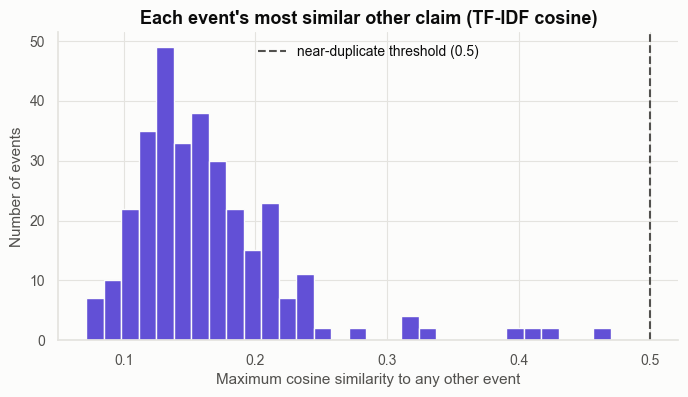

In [13]:
# Pairwise cosine similarity of claim texts (descriptive only)
dup_vec = TfidfVectorizer(stop_words="english", sublinear_tf=True)
sim = cosine_similarity(dup_vec.fit_transform(df["claim"]))
np.fill_diagonal(sim, 0)
iu = np.triu_indices_from(sim, k=1)
pairs = pd.DataFrame({"i": iu[0], "j": iu[1], "cosine": sim[iu]})
NEAR_DUP_THRESHOLD = 0.5
near = pairs[pairs["cosine"] >= NEAR_DUP_THRESHOLD].sort_values("cosine", ascending=False).copy()
for side in ("i", "j"):
    near[f"company_{side}"] = df["company"].to_numpy()[near[side]]
    near[f"date_{side}"] = df["date"].dt.date.to_numpy()[near[side]]
    near[f"label_{side}"] = df["attribution"].to_numpy()[near[side]]
near["same_company"] = near["company_i"] == near["company_j"]
print(f"Claim pairs with cosine >= {NEAR_DUP_THRESHOLD}: {len(near)} "
      f"({int(near['same_company'].sum())} from the same company); max similarity = {pairs['cosine'].max():.3f}")

# The 10 most similar pairs, whatever their score, so the reader can judge them
top_pairs = pairs.nlargest(10, "cosine").copy()
for side in ("i", "j"):
    top_pairs[f"company_{side}"] = df["company"].to_numpy()[top_pairs[side]]
    top_pairs[f"date_{side}"] = df["date"].dt.date.to_numpy()[top_pairs[side]]
    top_pairs[f"label_{side}"] = df["attribution"].to_numpy()[top_pairs[side]]
top_pairs["same_company"] = top_pairs["company_i"] == top_pairs["company_j"]
display(top_pairs.drop(columns=["i", "j"]).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sim.max(axis=1), bins=30, color=ACCENT, edgecolor=SURFACE)
ax.axvline(NEAR_DUP_THRESHOLD, color=TEXT2, linestyle="--", linewidth=1.5,
           label=f"near-duplicate threshold ({NEAR_DUP_THRESHOLD})")
ax.set_title("Each event's most similar other claim (TF-IDF cosine)")
ax.set_xlabel("Maximum cosine similarity to any other event")
ax.set_ylabel("Number of events")
ax.legend()
savefig(fig, "fig03_near_duplicate_similarity")

**Repeat companies.** Several companies appear more than once (e.g. successive layoff rounds). Before counting them we build a normalised **`company_group`** key (lower case, parenthetical aliases and legal suffixes such as *Inc., plc, Group, Holdings, International* removed), so that e.g. *Telstra* and *Telstra International* share a group.

In [14]:
LEGAL_SUFFIX_RE = (r"\b(?:inc|plc|corp|corporation|holdings?|group|n\s?v|ltd|limited|"
                   r"international|worldwide|& company)\b")

def company_key(name):
    """Normalised company key used as the grouping variable for splitting."""
    s = re.sub(r"\(.*?\)", " ", name.lower())       # drop parenthetical aliases
    s = s.replace(".", " ").replace(",", " ")
    s = re.sub(LEGAL_SUFFIX_RE, " ", s)
    return " ".join(s.split())

df["company_group"] = df["company"].map(company_key)
merged = (df.groupby("company_group")["company"].unique()
            .loc[lambda s: s.map(len) > 1])
print("Distinct companies:", df["company"].nunique(), "-> distinct company groups:", df["company_group"].nunique())
print("Groups that merge several spellings:", merged.to_dict())

# Repeat companies and the labels they carry
rep = (df.groupby("company_group")
         .agg(events=("event_id", "size"),
              labels=("attribution", lambda s: ", ".join(sorted(s))),
              n_distinct_labels=("attribution", "nunique"))
         .query("events > 1")
         .sort_values(["events", "n_distinct_labels"], ascending=False))
print(f"\nCompany groups with >1 event: {len(rep)} covering {int(rep['events'].sum())} events "
      f"({rep['events'].sum() / len(df):.1%} of rows); "
      f"{int((rep['n_distinct_labels'] > 1).sum())} of them carry more than one label.")
display(rep)

Distinct companies: 257 -> distinct company groups: 256
Groups that merge several spellings: {'telstra': array(['Telstra International', 'Telstra'], dtype=object)}

Company groups with >1 event: 42 covering 106 events (33.1% of rows); 18 of them carry more than one label.


,events,labels,n_distinct_labels
company_group,,,
amazon,5,"blamed, blamed, explicit, mixed, mixed",3
google,5,"blamed, blamed, blamed, blamed, mixed",2
ibm,5,"blamed, blamed, blamed, mixed, mixed",2
chegg,5,"mixed, mixed, mixed, mixed, mixed",1
tiktok,5,"blamed, blamed, blamed, blamed, blamed",1
telstra,4,"blamed, blamed, blamed, mixed",2
benchsci,3,"explicit, explicit, mixed",2
bird,3,"blamed, mixed, mixed",2
meta,3,"blamed, blamed, mixed",2


**Decision.**
- There are no exact duplicates, duplicate IDs, duplicate (company, date) pairs or identical claims. One source URL is shared by *Telstra* (Feb 2026, mixed) and *Telstra International* (Apr 2026, blamed): two separate events reported in the same article. No claim pair reaches a cosine similarity of 0.5, and the most similar pairs are mostly the same company's successive rounds. Nothing is removed.
- Records that look alike are **genuinely separate events** (different dates, rounds or announcements of the same company), so they stay in.
- The real risk is **related records**: the same company's events share names, executives and phrasing. If one round is in training and another in test, the model can "recognise" the company instead of reading the evidence. We handle this with (i) a **company-grouped split** (§6.6) and (ii) **masking company names** in the text (§6.1).

### 5.5 Harmonising Country and Sector
**Country** has 50 messy strings (e.g. *"United States (global workforce; no country split given)"*, *"Ireland, Singapore, Malaysia (…)"*). We derive:
- `country_primary`: the first country named, before any parenthesis or list separator;
- `multi_country`: 1 if the text lists several countries or describes a global footprint;
- `region`: a continent-level grouping of `country_primary`.

In [15]:
REGION_MAP = {
    "united states": "north_america", "canada": "north_america",
    "argentina": "latin_america",
    "united kingdom": "europe", "germany": "europe", "france": "europe", "netherlands": "europe",
    "italy": "europe", "sweden": "europe", "poland": "europe", "belgium": "europe",
    "switzerland": "europe", "norway": "europe", "spain": "europe", "ireland": "europe",
    "finland": "europe", "denmark": "europe", "portugal": "europe", "austria": "europe",
    "israel": "middle_east",
    "india": "asia_pacific", "australia": "asia_pacific", "singapore": "asia_pacific",
    "japan": "asia_pacific", "malaysia": "asia_pacific",
    "south africa": "africa", "nigeria": "africa",
    "global": "global",
}
MULTI_COUNTRY_RE = r"global|,|/|;| and |countries|worldwide|abroad"

def primary_country(text):
    """First country mentioned, ignoring parenthetical notes and list separators."""
    head = re.split(r"\(", text)[0]
    head = re.split(r",|/|;| and ", head)[0]
    return head.strip().lower()

df["country_raw"] = df["country"]
df["country_primary"] = df["country"].map(primary_country)
df["multi_country"] = df["country"].str.lower().str.contains(MULTI_COUNTRY_RE, regex=True).astype(int)
df["region"] = df["country_primary"].map(REGION_MAP)
assert df["region"].notna().all(), df.loc[df["region"].isna(), "country_primary"].unique()

print("Distinct country strings:", df["country_raw"].nunique(), "-> country_primary:", df["country_primary"].nunique())
display(df.loc[df["country_raw"].str.lower() != df["country_primary"],
               ["country_raw", "country_primary", "multi_country", "region"]].drop_duplicates().head(15))
display(df["region"].value_counts().rename("events").to_frame())

Distinct country strings: 50 -> country_primary: 28


,country_raw,country_primary,multi_country,region
11,Israel (company headquartered in the US),israel,0,middle_east
48,United States (global workforce; no country split given),united states,1,north_america
75,"Ireland, Singapore, Malaysia (global Trust and Safety reorganisation)",ireland,1,europe
79,United States (global workforce),united states,1,north_america
91,India (roles); Opendoor is a US company,india,1,asia_pacific
96,United States and India,united states,1,north_america
97,"Global (Guernsey-registered; about 4,000 to 5,000 of its staff are in Israel)",global,1,global
103,United States (San Francisco HQ; remote company with staff abroad),united states,1,north_america
104,Israel / United States (dual headquarters; operates in 25 countries),israel,1,middle_east
113,Ireland and United States,ireland,1,europe


,events
region,
north_america,166
europe,81
asia_pacific,38
middle_east,27
global,4
africa,3
latin_america,1


**Sector** has 228 free-text values for 320 rows, far too many to one-hot encode. We map them to **12 sector groups** with ordered keyword rules: the **first matching rule wins**, so specific groups (gaming, edtech, fintech) are checked before broad ones (software). Anything that matches no rule goes to `other`.

In [16]:
# Ordered keyword rules: (group, regex). First match wins.
SECTOR_RULES = [
    ("gaming", r"game|gaming|gambl|betting"),
    ("edtech", r"educat|edtech|course|upskilling|academic"),
    ("health_pharma", r"health|pharma|drug|vaccin"),
    ("fintech_crypto", r"fintech|payment|crypto|bitcoin|blockchain|digital asset|neobank|custody|credit scoring"),
    ("banking_insurance", r"bank|insurance|financial services"),
    ("telecom", r"telecom"),
    ("big_tech_internet", r"big tech|social|consumer internet|^internet|ridesharing|hardware|semiconductor|"
                          r"consumer technology|metaverse|ai models|consumer apps"),
    ("media_marketing", r"media|news|publish|journalism|broadcast|radio|entertainment|music|audience|"
                        r"advertising|marketing services|creator"),
    ("it_services_bpo_consulting", r"it services|it solutions|consult|bpo|call cent|contact centres|business process|"
                                   r"outsourc|reseller|^legal$|services$|technology / services|travel management|"
                                   r"digital operations"),
    ("commerce_travel", r"e-commerce|ecommerce|marketplace|retail|grocery|delivery|fashion|travel|airline|aviation|"
                        r"ticketing|resale|interiors|styling|tour"),
    ("industrial_consumer_goods", r"automotive|chemical|logistic|freight|consumer goods|tobacco|appliance|cpg|materials"),
    ("software_saas", r"software|saas|tech|cyber|data|cloud|dev|platform|\bai\b|artificial intelligence|analytics|"
                      r"intelligence|web|internet|digital|online|mobile|app|geolocation|maps|recruit|\bhr\b|infrastructure"),
]

def sector_group(text):
    """Map a free-text sector to a sector group using the first matching keyword rule."""
    s = text.lower()
    for group, pattern in SECTOR_RULES:
        if re.search(pattern, s):
            return group
    return "other"

df["sector_raw"] = df["sector"]
df["sector_group"] = df["sector"].map(sector_group)

sector_summary = (df.groupby("sector_group")
                    .agg(events=("event_id", "size"), raw_values=("sector_raw", "nunique"),
                         examples=("sector_raw", lambda s: " | ".join(s.value_counts().index[:3])))
                    .sort_values("events", ascending=False))
display(sector_summary)
other_values = df.loc[df["sector_group"] == "other", "sector_raw"].value_counts()
print(f"Values that ended up in 'other': {len(other_values)}", other_values.to_dict())
print("\nAll raw values in the broad 'software_saas' catch-all (check the rules are sensible):")
print(sorted(df.loc[df["sector_group"] == "software_saas", "sector_raw"].unique()))

,events,raw_values,examples
sector_group,,,
software_saas,90,72,Software | Cybersecurity software | Business messaging software (CPaaS)
big_tech_internet,36,21,Big Tech / Cloud | Big Tech / E-commerce / Cloud | Social media
banking_insurance,33,9,Banking | Digital banking | Banking (wealth management)
fintech_crypto,30,27,Fintech | Fintech / digital payments | Analytics software and credit scoring
commerce_travel,28,25,E-commerce software | Food delivery and quick commerce | online grocery technology and...
media_marketing,27,23,Media and entertainment | Newspaper publishing | Media/Journalism
it_services_bpo_consulting,18,15,IT services / BPO | Legal | IT services and consulting
telecom,15,4,Telecom | Telecommunications | Telecom software and IT services
industrial_consumer_goods,14,10,Automotive | Automotive software | Freight logistics software and brokerage


Values that ended up in 'other': 0 {}

All raw values in the broad 'software_saas' catch-all (check the rules are sensible):
['AI language technology (translation software)', 'AI transcription and captioning', 'AI translation software', 'Appointment booking software (beauty and wellness)', 'B2B sales data software', 'Beverage industry software', 'Business messaging software (CPaaS)', 'Business software (SaaS)', 'Cloud data software', 'Competitive intelligence software', 'Connected-car software', 'Consumer software (family safety and location app)', 'Contact-center software', 'Conversational AI software', 'Customer data software', 'Cybersecurity (SaaS and managed services)', 'Cybersecurity (SaaS)', 'Cybersecurity (managed detection and response / security operations)', 'Cybersecurity (managed detection and response)', 'Cybersecurity Software', 'Cybersecurity software', 'Data infrastructure software (cloud data warehouse)', 'Data security and privacy software', 'Design software', 'Dev To

**Decision.** Country is reduced from 50 strings to a handful of primary countries plus 7 regions and a `multi_country` flag. Sector is reduced from 228 strings to 12 groups, and **no value falls into `other`**, so every raw sector is covered by a rule. `software_saas` is a deliberate catch-all for enterprise and consumer software; it is the largest group, which matches the register's tech-heavy coverage. The raw columns are kept for reference but not used as features. Rare `country_primary` levels are folded into an "infrequent" bucket by the encoder (`min_frequency=3`).

### 5.6 Outliers in headcount
Layoff sizes range from a handful of roles to tens of thousands, so we expect a heavy right tail. We apply the IQR rule on the raw scale and on the log scale.

count      257.0
mean      1439.0
std       2912.8
min          3.0
25%        100.0
50%        281.0
75%       1000.0
max      21000.0

Raw scale : fences [-1,250, 2,350] -> 44 outliers
Log scale : fences [2.2, 31,231] -> 0 outliers


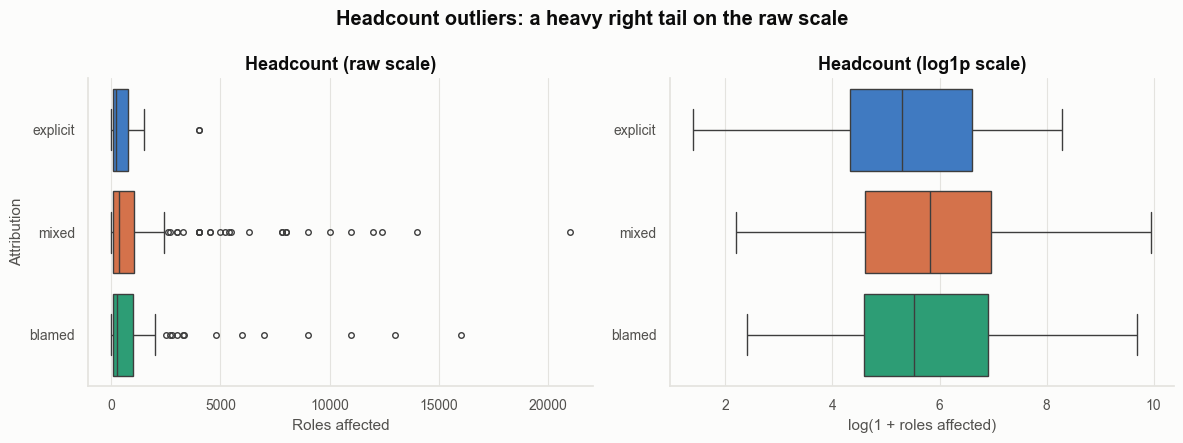

,company,date,headcount,kind,attribution
82,Oracle,2026-06-22,21000.0,cut,mixed
184,Amazon,2026-01-28,16000.0,cut,blamed
211,Amazon,2025-10-28,14000.0,cut,mixed
203,Verizon,2025-11-20,13000.0,cut,blamed
182,Intesa Sanpaolo,2026-02-02,12400.0,cut,mixed
238,Tata Consultancy Services (TCS),2025-07-27,12000.0,cut,mixed
162,Dell Technologies,2026-03-16,11000.0,cut,blamed
224,Accenture,2025-09-25,11000.0,cut,mixed
315,BT Group,2023-05-18,10000.0,cut,mixed
244,Microsoft,2025-07-02,9000.0,cut,blamed


In [17]:
def iqr_bounds(s):
    """Return the (lower, upper) Tukey fences: Q1 - 1.5*IQR, Q3 + 1.5*IQR."""
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

hc = df["headcount"].dropna()
log_hc = np.log1p(hc)
lo, hi = iqr_bounds(hc)
llo, lhi = iqr_bounds(log_hc)
print(hc.describe().round(1).to_string())
print(f"\nRaw scale : fences [{lo:,.0f}, {hi:,.0f}] -> {int(((hc < lo) | (hc > hi)).sum())} outliers")
print(f"Log scale : fences [{np.expm1(llo):,.1f}, {np.expm1(lhi):,.0f}] -> "
      f"{int(((log_hc < llo) | (log_hc > lhi)).sum())} outliers")

df["log_headcount"] = np.log1p(df["headcount"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="headcount", y="attribution", hue="attribution", order=CLASSES,
            palette=CLASS_COLORS, legend=False, ax=axes[0], fliersize=4)
axes[0].set_title("Headcount (raw scale)")
axes[0].set_xlabel("Roles affected")
axes[0].set_ylabel("Attribution")
sns.boxplot(data=df, x="log_headcount", y="attribution", hue="attribution", order=CLASSES,
            palette=CLASS_COLORS, legend=False, ax=axes[1], fliersize=4)
axes[1].set_title("Headcount (log1p scale)")
axes[1].set_xlabel("log(1 + roles affected)")
axes[1].set_ylabel("")
fig.suptitle("Headcount outliers: a heavy right tail on the raw scale", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig04_headcount_outliers")

display(df.nlargest(10, "headcount")[["company", "date", "headcount", "kind", "attribution"]])

**Decision.** The largest events (tens of thousands of roles at very large employers) are **genuine**: they are documented by sources, not data-entry errors. Removing them would delete real, important events. We **keep all values** and add `log_headcount = log(1 + headcount)`, which compresses the tail so that no outliers remain on the log scale. Models in Part 2 use `log_headcount` (scaled with training statistics), never raw `headcount`.

## 6. Preprocessing and transformations
### 6.1 Text cleaning and company-name masking
Model text = **claim + source title**. Steps:
1. **Mask the event's own company name** (and its aliases, e.g. *Bank of America → BofA*, *Block (Square) → Square*, legal suffixes stripped) with the token `companyname`. Masking is case-sensitive on the original text, so ordinary words such as "block" or "square" in other contexts are left alone. Without masking, company names dominate the top χ² terms and the model would memorise companies instead of learning attribution language.
2. Lower-case, remove URLs, replace numbers with `num`, strip punctuation, collapse whitespace.

In [18]:
# Alias handling for company masking
NAME_SUFFIX_RE = (r"(?:,?\s+(?:Inc\.?|plc|PLC|Corporation|Corp\.?|N\.V\.|Holdings?|Holding Corp\.|Group|"
                  r"Worldwide|& Company|Software|Technologies|Systems|International))+$")
MANUAL_ALIASES = {   # well-known short forms that appear in the claims
    "Bank of America": ["BofA"], "JPMorgan Chase": ["JPMorgan", "JP Morgan", "J.P. Morgan"],
    "General Motors": ["GM"], "Procter & Gamble": ["P&G"], "National Australia Bank": ["NAB"],
    "Commonwealth Bank": ["CBA", "CommBank"], "Google": ["Alphabet"], "Meta": ["Facebook"],
    "British American Tobacco": ["BAT"], "Tata Consultancy Services (TCS)": ["Tata"],
    "Commerce.com (BigCommerce)": ["Commerce.com"], "Wix.com": ["Wix"], "Gizmodo en Español": ["Gizmodo"],
    "Bendigo and Adelaide Bank": ["Bendigo", "Bendigo Bank"], "Bolt Financial": ["Bolt"],
    "Just Eat Takeaway": ["Just Eat", "Takeaway.com"], "Papaya Gaming": ["Papaya"], "Starling Bank": ["Starling"],
    "Telenor Norge": ["Telenor"], "Vodafone Germany": ["Vodafone"], "Rackspace Technology": ["Rackspace"],
    "WiseTech Global": ["WiseTech"],
}
GENERIC_ALIASES = {"People", "Freight", "Commerce", "General", "National"}   # too generic to mask
# Aliases that are also ordinary words: matched case-sensitively only. All others match in any case.
CASE_SENSITIVE_ALIASES = {"Block", "Square", "Bird", "Snap", "Chime", "Visa", "Sunrise", "Apple", "Dune", "Bolt",
                          "Gemini", "Papaya", "Starling", "Just Eat", "Meta", "Uber", "Angi", "Klue", "Mews", "Skai",
                          "Envato", "ING", "BT", "GM", "BAT", "NAB", "CBA", "HP", "UPS", "IAC", "EXL", "WPP"}

def company_aliases(name):
    """All surface forms of a company name to mask, longest first."""
    aliases = {name, re.sub(r"\s*\(.*?\)", "", name).strip()}
    for inner in re.findall(r"\((.*?)\)", name):                      # e.g. "Bird (MessageBird)"
        aliases.update(p.strip() for p in re.split(r"/|,|;| and ", inner))
    for a in list(aliases):                                          # e.g. "IAC / People Inc."
        aliases.update(p.strip() for p in re.split(r"\s*/\s*", a))
    for a in list(aliases):
        stripped = re.sub(NAME_SUFFIX_RE, "", a).strip()
        aliases.add(stripped)
        if stripped.startswith("The "):
            aliases.add(stripped[4:])
        words = stripped.split()
        if len(words) > 1 and re.fullmatch(r"[A-Z0-9&]{2,}", words[0]):   # leading acronym, e.g. "BT Group"
            aliases.add(words[0])
    aliases.update(MANUAL_ALIASES.get(name, []))
    return sorted({a for a in aliases if len(a) >= 2 and a not in GENERIC_ALIASES}, key=len, reverse=True)

def mask_company(text, aliases):
    """Replace every alias (plus possessive 's) with the token 'companyname'.
    Short or dictionary-like aliases match case-sensitively; distinctive ones match in any case (e.g. TELUS, SSENSE)."""
    if not text:
        return text
    for a in aliases:                                   # aliases are sorted longest first
        flags = 0 if (a in CASE_SENSITIVE_ALIASES or len(a) < 5) else re.IGNORECASE
        text = re.sub(r"(?<!\w)" + re.escape(a) + r"(?:['’]s)?(?!\w)", " companyname ", text, flags=flags)
    return text

def clean_text(text):
    """Lowercase, drop URLs, numbers -> 'num', strip punctuation, collapse whitespace."""
    t = str(text).lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"\d+(?:[.,]\d+)*", " num ", t)
    t = re.sub(r"[^\w\s]|_", " ", t)
    return " ".join(t.split())

df["claim"] = df["claim"].fillna("")
df["source_title"] = df["source_title"].fillna("")
df["company_aliases"] = df["company"].map(company_aliases)
df["claim_masked"] = [mask_company(t, a) for t, a in zip(df["claim"], df["company_aliases"])]
df["source_masked"] = [mask_company(t, a) for t, a in zip(df["source_title"], df["company_aliases"])]
df["claim_clean"] = df["claim_masked"].map(clean_text)
df["source_clean"] = df["source_masked"].map(clean_text)
df["text_clean"] = (df["claim_clean"] + " " + df["source_clean"]).str.strip()

# Register "verdict" phrases inside the claim (e.g. "The memo does not mention AI", "gave no AI reason").
# They are genuine evidence, but they almost restate the blamed definition, so we flag them (audited in 6.5)
# and keep a variant of the text without them for a Part 2 sensitivity check.
VERDICT_RE = (r"(?:does|did|do|has|have|had) not (?:name|mention|cite|attribute|give|link)\w*[^.;:]{0,40}?"
              r"\b(?:ai|artificial intelligence|automation)\b(?: as (?:the|a) (?:cause|reason))?"
              r"|never (?:named|mentioned|cited) (?:ai|artificial intelligence)|(?:gave|gives|named|cited) no ai reason"
              r"|no ai reason|makes no mention of (?:ai|artificial intelligence)|no mention of (?:ai|artificial intelligence)"
              r"|did not attribute[^.;:]{0,60}?\bai\b")
df["claim_has_verdict_phrase"] = df["claim_masked"].str.lower().str.contains(VERDICT_RE, regex=True).astype(int)
claim_noverdict = [re.sub(VERDICT_RE, " ", t, flags=re.IGNORECASE) for t in df["claim_masked"]]
df["text_clean_noverdict"] = [(clean_text(c) + " " + s).strip() for c, s in zip(claim_noverdict, df["source_clean"])]
print("Claims with a register verdict phrase, by class:",
      df.groupby("attribution")["claim_has_verdict_phrase"].sum().reindex(CLASSES).to_dict())

masked_share = df["claim_clean"].str.contains(r"\bcompanyname\b", regex=True).mean()
print(f"Claims containing at least one masked company mention: {masked_share:.1%}")

# Residual check: does the first word of the company name (>= 4 letters) survive in its own cleaned text?
residual = sorted({(comp, w) for comp, t in zip(df["company"], df["text_clean"])
                   for w in [re.sub(r"[^\w]", "", comp.split()[0].lower())]
                   if len(w) >= 4 and re.search(r"\b" + re.escape(w) + r"\b", t)})
print("Residual first-word matches (generic words, kept deliberately):", residual)
print("Example aliases:", {c: company_aliases(c) for c in ["Bank of America", "Block (Square)", "BT Group", "IAC / People Inc."]})

Claims with a register verdict phrase, by class: {'explicit': 0, 'mixed': 1, 'blamed': 12}
Claims containing at least one masked company mention: 83.8%
Residual first-word matches (generic words, kept deliberately): [('Freight Technologies (Fr8Tech)', 'freight'), ('Radio Kraków', 'radio')]
Example aliases: {'Bank of America': ['Bank of America', 'BofA'], 'Block (Square)': ['Block (Square)', 'Square', 'Block'], 'BT Group': ['BT Group', 'BT'], 'IAC / People Inc.': ['IAC / People Inc.', 'IAC / People', 'People Inc.', 'IAC']}


In [19]:
# Before / after example of the full text pipeline
ex = df.loc[df["company"] == "Kroger"].iloc[0]
print("RAW CLAIM   :", ex["claim"][:400], "...")
print("\nRAW SOURCE  :", ex["source_title"])
print("\nCLEAN TEXT  :", ex["text_clean"][:400], "...")

RAW CLAIM   : Reuters (2026-10-12): "Kroger plans to cut roughly 3,000 corporate roles over the next three years, CEO Greg Foran told staff in a memo, seen by Reuters on Monday, as the grocer integrates AI into its workflow." Foran's memo (full text published by Business Insider, which says Kroger shared it) gives as reasons: "Our company has more layers, more handoffs and more overhead than we need, so we are  ...

RAW SOURCE  : Reuters via AOL: Kroger plans to eliminate 3,000 corporate roles, memo shows, as it expands AI use

CLEAN TEXT  : reuters num num num companyname plans to cut roughly num corporate roles over the next three years ceo greg foran told staff in a memo seen by reuters on monday as the grocer integrates ai into its workflow foran s memo full text published by business insider which says companyname shared it gives as reasons our company has more layers more handoffs and more overhead than we need so we are address ...


### 6.2 Date features
Calendar features plus a linear trend (`months_since_start`) and a **cyclical** encoding of the month (sine/cosine), so that December and January are close together.

In [20]:
start = df["date"].min()
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["quarter"] = df["date"].dt.quarter
df["year_quarter"] = df["year"].astype(str) + "Q" + df["quarter"].astype(str)
df["months_since_start"] = (df["year"] - start.year) * 12 + (df["month"] - start.month)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
df[["date", "year", "month", "quarter", "year_quarter", "months_since_start", "month_sin", "month_cos"]].head()

,date,year,month,quarter,year_quarter,months_since_start,month_sin,month_cos
0,2026-10-22,2026,10,4,2026Q4,44,-0.866025,0.5
1,2026-10-20,2026,10,4,2026Q4,44,-0.866025,0.5
2,2026-10-20,2026,10,4,2026Q4,44,-0.866025,0.5
3,2026-10-17,2026,10,4,2026Q4,44,-0.866025,0.5
4,2026-10-16,2026,10,4,2026Q4,44,-0.866025,0.5


### 6.3 Parsing "% of workforce"
This column is free text such as *"about 5% of employees"*, *"10–15%"*, *"about a third"* or *"up to 400 of about 3,200 staff"*. Rules, applied in order:
1. a range `a–b %` → its midpoint; 2. the first `x %`; 3. a fraction word (*two-thirds, half, third, quarter, fifth, tenth*); 4. `n of N staff/employees/workers` → 100·n/N. Anything else (e.g. *"low single digits"*) → NaN.

In [21]:
FRACTION_WORDS = [("two-thirds", 66.7), ("two thirds", 66.7), ("half", 50.0), ("third", 33.3),
                  ("quarter", 25.0), ("fifth", 20.0), ("tenth", 10.0)]

def parse_pct(text):
    """Convert a free-text workforce share into a percentage (float) or NaN."""
    if pd.isna(text):
        return np.nan
    t = text.lower()
    m = re.search(r"(\d+(?:\.\d+)?)\s*%?\s*(?:-|–|to)\s*(\d+(?:\.\d+)?)\s*%", t)
    if m:
        return (float(m.group(1)) + float(m.group(2))) / 2
    m = re.search(r"(\d+(?:\.\d+)?)\s*%", t)
    if m:
        return float(m.group(1))
    for word, value in FRACTION_WORDS:
        if re.search(r"\b" + word, t):
            return value
    m = re.search(r"(\d[\d,]*) of (?:about |roughly |~)?(\d[\d,]*) (?:staff|employees|workers|people)", t)
    if m:
        return 100 * float(m.group(1).replace(",", "")) / float(m.group(2).replace(",", ""))
    return np.nan

df["pct_workforce"] = df["pct_of_workforce"].map(parse_pct)
n_text = int(df["pct_of_workforce"].notna().sum())
n_parsed = int(df["pct_workforce"].notna().sum())
print(f"Non-missing text values: {n_text}; parsed to a number: {n_parsed} ({n_parsed / n_text:.1%})")
print("Not parseable (left as NaN):")
for s in df.loc[df["pct_of_workforce"].notna() & df["pct_workforce"].isna(), "pct_of_workforce"]:
    print("   -", s)
display(df.loc[df["pct_workforce"].notna(), ["pct_of_workforce", "pct_workforce"]].sample(6, random_state=RANDOM_STATE))
print(df["pct_workforce"].describe().round(2).to_string())

Non-missing text values: 215; parsed to a number: 210 (97.7%)
Not parseable (left as NaN):
   - Undisclosed (the company declined a figure; a ~700 number circulating online is unverified forum speculation)
   - low single digits (company)
   - 10 of 12 technical writers (press)
   - low single digits (CEO)
   - of 55,000 total cuts


,pct_of_workforce,pct_workforce
51,about 6% (Scripps' release: 'transformation-related job reductions communicated on Tue...,6.0
265,9%,9.0
127,"about 10% (200 against just over 1,980 employees on payroll at March 31, 2026, both co...",10.0
302,"under 5% (fewer than about 260 of the about 5,200 full-time colleagues at December 31,...",5.0
94,about 20% (Calcalist; not stated by the company),20.0
235,~11.5% average-employee-headcount decline in 2025 (company-disclosed),11.5


count    210.00
mean      17.30
std       14.18
min        0.05
25%        7.00
50%       14.00
75%       23.00
max       90.00


### 6.4 Multi-hot encoding of job families
`job_families` lists up to several of 11 standard families separated by semicolons. We create one binary `jf_*` column per family plus `n_job_families`. "Not specified" becomes all zeros (`n_job_families = 0`).

In [22]:
jf_lists = df["job_families"].fillna("").str.split(";").map(
    lambda parts: [p.strip() for p in parts if p.strip() and not re.match(PLACEHOLDER_RE, p.strip(), re.I)])
JOB_FAMILIES = sorted({f for lst in jf_lists for f in lst})

def jf_col(family):
    """Column name for a job family, e.g. 'Software engineering and IT' -> 'jf_software_engineering_and_it'."""
    return "jf_" + re.sub(r"[^0-9a-z]+", "_", family.lower()).strip("_")

JF_COLS = [jf_col(f) for f in JOB_FAMILIES]
for fam, col in zip(JOB_FAMILIES, JF_COLS):
    df[col] = jf_lists.map(lambda lst, fam=fam: int(fam in lst))
df["n_job_families"] = df[JF_COLS].sum(axis=1)
display(df[JF_COLS].sum().sort_values(ascending=False).rename("events").to_frame())

,events
jf_software_engineering_and_it,83
jf_corporate_functions,60
jf_sales_and_marketing,48
jf_customer_service_and_support,43
jf_management_layers,41
jf_operations_and_back_office,39
jf_product_and_design,27
jf_writing_editorial_and_translation,27
jf_consulting_and_professional_services,5
jf_content_moderation,5


### 6.5 Leakage audit
Some columns are written by the register **after** it has decided the attribution, or they encode that decision directly. We measure the association of each candidate column with `Attribution` using **bias-corrected Cramér's V** (Bergsma, 2013). V = 0 means no association and V = 1 means the column fully determines the label. This is a property of the columns themselves, not a fitted feature transformation, so we compute it on the full dataset for the audit.

In [23]:
def cramers_v(x, y):
    """Bias-corrected Cramér's V between two categorical series (Bergsma 2013)."""
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return 0.0
    chi2_stat = chi2_contingency(ct, correction=False)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = chi2_stat / n
    phi2corr = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rcorr = r - (r - 1) ** 2 / (n - 1)
    kcorr = k - (k - 1) ** 2 / (n - 1)
    denom = min(kcorr - 1, rcorr - 1)
    return float(np.sqrt(phi2corr / denom)) if denom > 0 else 0.0

# Short reason category for 'why_not_counted' (first clause before ';')
df["why_not_counted_reason"] = (df["why_not_counted"].fillna("(empty: counted)").str.split(";").str[0]
                                .str.rstrip("."))

LEAKAGE_CANDIDATES = {
    "what_the_employer_said": df["what_the_employer_said"],
    "why_not_counted (first clause)": df["why_not_counted_reason"],
    "why_not_counted mentions 'has not named AI'": df["why_not_counted"].fillna("").str.contains("has not named AI"),
    "evidence_tier": df["evidence_tier"],
    "counts_in_us_index": df["counts_in_us_index"],
    "roles_counted is NaN": df["roles_counted"].isna(),
    "roles_reported_not_counted is NaN": df["roles_reported_not_counted"].isna(),
    # text-level check: register verdict wording inside the claim (flagged, see decision below)
    "claim has register verdict phrase": df["claim_has_verdict_phrase"],
    # legitimate inputs, for comparison
    "headcount (merged) is NaN": df["headcount"].isna(),
    "kind": df["kind"],
    "execution": df["execution"],
    "sector_group": df["sector_group"],
    "region": df["region"],
    "pct_workforce is NaN": df["pct_workforce"].isna(),
}
LEAKY = {"what_the_employer_said", "why_not_counted (first clause)", "why_not_counted mentions 'has not named AI'",
         "evidence_tier", "counts_in_us_index", "roles_counted is NaN", "roles_reported_not_counted is NaN"}
leak_tbl = pd.DataFrame({
    "cramers_v": {k: cramers_v(v, df["attribution"]) for k, v in LEAKAGE_CANDIDATES.items()},
    "levels": {k: pd.Series(v).nunique() for k, v in LEAKAGE_CANDIDATES.items()},
})
leak_tbl["decision"] = np.where(leak_tbl.index.isin(list(LEAKY)), "EXCLUDE (leakage)", "keep as input")
leak_tbl.loc["claim has register verdict phrase", "decision"] = "FLAG (kept in text; sensitivity check in Part 2)"
leak_tbl = leak_tbl.sort_values("cramers_v", ascending=False).round(3)
leak_tbl

,cramers_v,levels,decision
what_the_employer_said,0.947,7,EXCLUDE (leakage)
why_not_counted mentions 'has not named AI',0.824,2,EXCLUDE (leakage)
why_not_counted (first clause),0.622,10,EXCLUDE (leakage)
evidence_tier,0.404,3,EXCLUDE (leakage)
kind,0.403,2,keep as input
roles_reported_not_counted is NaN,0.381,2,EXCLUDE (leakage)
roles_counted is NaN,0.371,2,EXCLUDE (leakage)
claim has register verdict phrase,0.305,2,FLAG (kept in text; sensitivity check in Part 2)
pct_workforce is NaN,0.225,2,keep as input
sector_group,0.208,12,keep as input


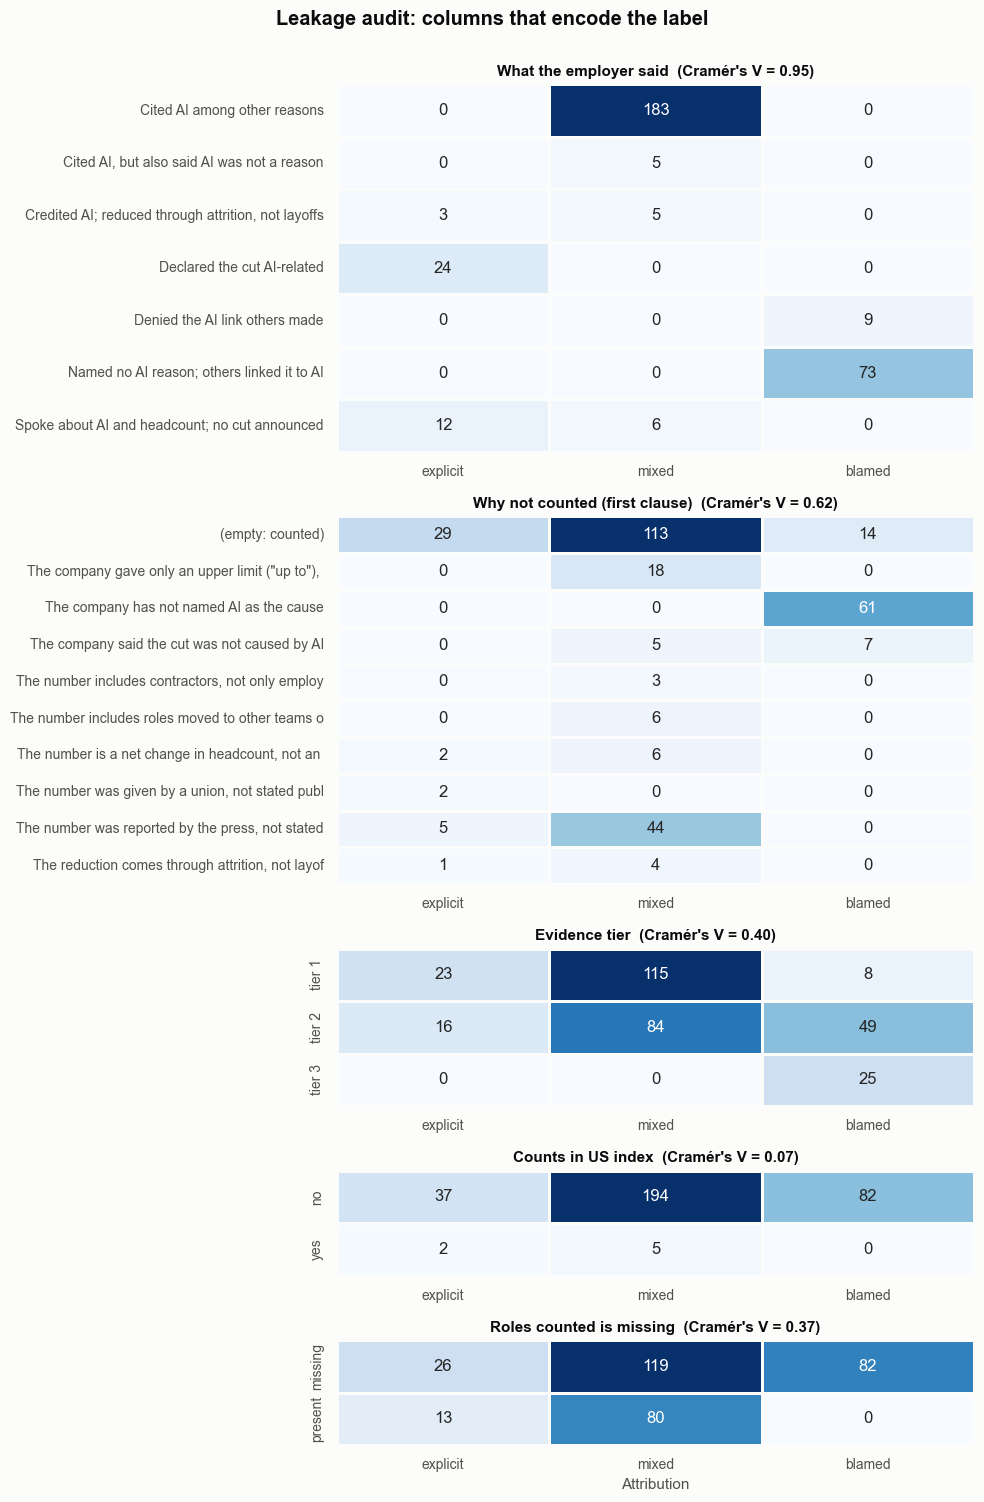

In [24]:
# Crosstab heatmaps for the leaking columns (row = column value, cell = number of events)
leak_views = {
    "What the employer said": df["what_the_employer_said"],
    "Why not counted (first clause)": df["why_not_counted_reason"].str.slice(0, 48),
    "Evidence tier": df["evidence_tier"],
    "Counts in US index": df["counts_in_us_index"],
    "Roles counted is missing": df["roles_counted"].isna().map({True: "missing", False: "present"}),
}
fig, axes = plt.subplots(len(leak_views), 1, figsize=(10, 15),
                         gridspec_kw={"height_ratios": [7, 7, 3, 2, 2]})
for ax, (title, col) in zip(axes, leak_views.items()):
    ct = pd.crosstab(col, df["attribution"]).reindex(columns=CLASSES, fill_value=0)
    sns.heatmap(ct, annot=True, fmt="d", cmap=SEQ_CMAP, cbar=False, linewidths=1, linecolor=SURFACE, ax=ax)
    ax.set_title(f"{title}  (Cramér's V = {cramers_v(col, df['attribution']):.2f})", fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes[-1].set_xlabel("Attribution")
fig.suptitle("Leakage audit: columns that encode the label", fontweight="bold", y=1.0)
fig.tight_layout()
savefig(fig, "fig05_leakage_crosstabs")

**What we see / Decision.** The audit confirms the columns that encode the label:
- **`what_the_employer_said`** (V ≈ 0.95) restates the label: five of its seven values occur in exactly one class (*"Cited AI among other reasons"* → 183 mixed, *"Named no AI reason; others linked it to AI"* → 73 blamed, *"Declared the cut AI-related"* → 24 explicit). → **excluded**.
- **`why_not_counted`**: the phrase *"has not named AI as the cause"* occurs **only** for blamed events (V ≈ 0.82 for that flag alone). → **excluded**.
- **`evidence_tier`**: Tier 3 (25 events) is **100 % blamed**. Its overall V (≈ 0.40) looks similar to `kind`, but it is the register's own assessment of the evidence, made together with the label. → **excluded from features, kept for EDA**.
- **`counts_in_us_index`**: weakly associated (V ≈ 0.07, only 7 "yes" events, none blamed), but excluded on **principle**: it is a post-assessment output of the register's counting rules, not available for a new event.
- **`roles_counted` vs `roles_reported_not_counted`**: blamed numbers are *never* in `roles_counted` (V ≈ 0.37), so *which* column holds the number is decided by the label. → both **excluded**; the merged **`headcount`** is kept (its missingness has V ≈ 0.18, driven by explicit workforce statements without a number).
- **Text-level check: verdict phrases inside `claim`.** A few claims contain the register's own summary of the employer's silence (*"the memo does not mention AI"*, *"gave no AI reason"*): 12 blamed, 1 mixed and 0 explicit claims. This *is* evidence about what the employer said, which is exactly what the label measures, so we keep it in `text_clean`. Because it sits close to a restatement of the label, we also save `text_clean_noverdict` (phrases removed). Part 2 should report text results **with and without** these phrases.

The kept context inputs (`kind`, `execution`, `sector_group`, `region`) have moderate or low association, as genuine context should. `kind = workforce statement` never occurs for blamed events, but that describes what the employer did (talked about AI and headcount without announcing a cut), not how the register classified it, so it stays as a legitimate input.

### 6.6 Group-aware train/test split (created before any fitting)
We split on `company_group` with `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`: fold 0 (~20 %) is the **test set**, and the other four folds form the training set. Each row also keeps its fold id (`sgkf_fold`), so Part 2 can reuse folds 1–4 for **grouped cross-validation on the training data**. We also add `chrono_split`, which marks the most recent ~20 % of events by date, for a time-based robustness check in Part 2.

In [25]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
df["sgkf_fold"] = -1
for fold, (_, test_idx) in enumerate(sgkf.split(df, df["attribution"], groups=df["company_group"])):
    df.loc[df.index[test_idx], "sgkf_fold"] = fold
assert (df["sgkf_fold"] >= 0).all()
df["split"] = np.where(df["sgkf_fold"] == 0, "test", "train")

# No company group may appear in both sets
overlap = set(df.loc[df["split"] == "train", "company_group"]) & set(df.loc[df["split"] == "test", "company_group"])
assert len(overlap) == 0, overlap
# Check on the raw company names as well
assert not set(df.loc[df["split"] == "train", "company"]) & set(df.loc[df["split"] == "test", "company"])

# Chronological holdout: the most recent ~20% of events
n_recent = int(round(0.2 * len(df)))
recent_idx = df.sort_values(["date", "event_id"]).index[-n_recent:]
df["chrono_split"] = np.where(df.index.isin(recent_idx), "test", "train")

split_tbl = pd.crosstab(df["split"], df["attribution"], margins=True).reindex(columns=CLASSES + ["All"])
split_pct = pd.crosstab(df["split"], df["attribution"], normalize="index").reindex(columns=CLASSES).mul(100).round(1)
print("Group split: company overlap between train and test =", len(overlap))
display(split_tbl)
display(split_pct.rename(columns=lambda c: f"{c} %"))
print("Events per fold:", df["sgkf_fold"].value_counts().sort_index().to_dict())

chrono_cut = df.loc[df["chrono_split"] == "test", "date"].min().date()
chrono_overlap = (set(df.loc[df["chrono_split"] == "train", "company_group"])
                  & set(df.loc[df["chrono_split"] == "test", "company_group"]))
print(f"\nChronological split: test = events on/after {chrono_cut} ({n_recent} events); "
      f"companies in both chrono train and test: {len(chrono_overlap)}")
display(pd.crosstab(df["chrono_split"], df["attribution"]).reindex(columns=CLASSES))

train_mask = df["split"].eq("train").to_numpy(dtype=bool)
test_mask = ~train_mask
train_df, test_df = df.loc[train_mask].copy(), df.loc[test_mask].copy()
y_train, y_test = train_df["attribution"], test_df["attribution"]
print("Train:", train_df.shape, " Test:", test_df.shape)

Group split: company overlap between train and test = 0


attribution,explicit,mixed,blamed,All
split,,,,
test,7,45,23,75
train,32,154,59,245
All,39,199,82,320


attribution,explicit %,mixed %,blamed %
split,,,
test,9.3,60.0,30.7
train,13.1,62.9,24.1


Events per fold: {0: 75, 1: 63, 2: 55, 3: 64, 4: 63}

Chronological split: test = events on/after 2026-07-15 (64 events); companies in both chrono train and test: 11


attribution,explicit,mixed,blamed
chrono_split,,,
test,3,40,21
train,36,159,61


Train: (245, 61)  Test: (75, 61)


**Decision.** The test set has **no company in common** with the training set, and its class proportions are close to the training proportions, so stratification worked despite the grouping constraint. Everything fitted from here on (TF-IDF vocabularies, encoders, imputers, scalers, χ² / mutual-information scores) uses **`train_df` only**. The chronological split is stored for Part 2. Some companies appear on both sides of it, which is acceptable for a time-drift check but must be noted when interpreting it.

### 6.7 Preprocessing pipeline: `make_preprocessor(use_text, use_context)`
A scikit-learn `ColumnTransformer` that builds the feature matrix for each experiment:

| Block | Columns | Transformer |
|---|---|---|
| text | `text_clean` | `TfidfVectorizer(ngram_range=(1,2), stop_words="english", min_df=2, sublinear_tf=True)` |
| text statistics | engineered numeric text features (added in §7) | median imputer → `StandardScaler` |
| context categorical | sector_group, region, country_primary, kind, execution | `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=3)` |
| context numeric | log_headcount, pct_workforce, date features, n_job_families | median imputer → `StandardScaler` |
| context binary | flags and job-family indicators | passthrough |

The column lists live in a `spec` dictionary, so this section uses a **base** spec and §7 extends it with the engineered features. The preprocessor is fitted on the training split only.

In [26]:
# Base feature specification (extended in Section 7)
BASE_SPEC = {
    "text": "text_clean",
    "text_numeric": [],
    "text_binary": [],
    "context_categorical": ["sector_group", "region", "country_primary", "kind", "execution"],
    "context_numeric": ["log_headcount", "pct_workforce", "year", "months_since_start",
                        "month_sin", "month_cos", "n_job_families"],
    "context_binary": ["multi_country", "has_headcount", "has_pct_workforce"] + JF_COLS,
}
df["has_headcount"] = df["headcount"].notna().astype(int)
df["has_pct_workforce"] = df["pct_workforce"].notna().astype(int)
train_df, test_df = df.loc[train_mask].copy(), df.loc[test_mask].copy()

def numeric_pipe():
    """Median imputation followed by standardisation (both fitted on train)."""
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])

def make_preprocessor(use_text=True, use_context=True, spec=None):
    """ColumnTransformer for the text-only, context-only or combined configuration."""
    spec = spec or BASE_SPEC
    blocks = []
    if use_text:
        blocks.append(("tfidf", TfidfVectorizer(ngram_range=(1, 2), stop_words="english",
                                                min_df=2, sublinear_tf=True), spec["text"]))
        if spec["text_numeric"]:
            blocks.append(("text_num", numeric_pipe(), spec["text_numeric"]))
        if spec["text_binary"]:
            blocks.append(("text_bin", "passthrough", spec["text_binary"]))
    if use_context:
        blocks.append(("ctx_cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=3),
                       spec["context_categorical"]))
        blocks.append(("ctx_num", numeric_pipe(), spec["context_numeric"]))
        blocks.append(("ctx_bin", "passthrough", spec["context_binary"]))
    if not blocks:
        raise ValueError("use_text and use_context cannot both be False")
    return ColumnTransformer(blocks, remainder="drop", sparse_threshold=0.3)

CONFIGS = {"Exp 1: text only": (True, False), "Exp 2: context only": (False, True), "Exp 3: combined": (True, True)}

def config_shapes(spec):
    """Fit each configuration on train, transform train and test, and report the matrix shapes."""
    rows = []
    for name, (t, c) in CONFIGS.items():
        pre = make_preprocessor(t, c, spec).fit(train_df)
        Xtr, Xte = pre.transform(train_df), pre.transform(test_df)
        rows.append({"config": name, "train shape": Xtr.shape, "test shape": Xte.shape,
                     "sparse": hasattr(Xtr, "tocsr")})
    return pd.DataFrame(rows).set_index("config")

display(config_shapes(BASE_SPEC))
tfidf_vocab = make_preprocessor(True, False).fit(train_df).named_transformers_["tfidf"].vocabulary_
print(f"TF-IDF vocabulary learned from train only: {len(tfidf_vocab)} uni/bi-grams")

,train shape,test shape,sparse
config,,,
Exp 1: text only,"(245, 2098)","(75, 2098)",True
Exp 2: context only,"(245, 62)","(75, 62)",False
Exp 3: combined,"(245, 2160)","(75, 2160)",True


TF-IDF vocabulary learned from train only: 2098 uni/bi-grams


## 7. Feature engineering and selection
### 7.1 Engineered features
Hand-crafted features that describe *how* the evidence is written. They are computed per row with fixed regular expressions, so nothing is learned from the data and nothing can leak:

| Feature | Idea |
|---|---|
| `claim_word_count`, `claim_number_count`, `claim_quote_count` | length, numeric detail and number of direct quotations |
| `ai_term_count` | mentions of AI / automation / generative AI / LLMs / agents |
| `business_reason_count` | other business reasons: cost, restructuring, efficiency, margins, simplification … |
| `third_party_count` | third-party reporting: *according to, reported, union, sources, people familiar, analysts* |
| `ai_negation_count` | phrases that deny an AI link (*"not because of AI"*, *"unrelated to AI"*, *"denied"*) |
| `source_is_company` | the source title starts with the company's own name (first-party source) |
| `source_is_filing` | the source is a filing / results / earnings call / press release (8-K, 10-Q …) |
| `is_us`, `n_job_families`, `has_headcount`, `has_pct_workforce` | context flags |

In [27]:
AI_TERMS_RE = (r"\b(?:ai|a\.i\.|artificial intelligence|automation|automate[ds]?|automating|gen ?ai|generative|"
               r"llms?|large language models?|machine learning|chatbots?|agentic|ai agents?|copilot|chatgpt)\b")
BUSINESS_RE = (r"\b(?:costs?|cost-cutting|restructur\w*|efficien\w*|reorgani[sz]\w*|simplif\w*|margins?|"
               r"profitab\w*|economic|macro\w*|streamlin\w*|realign\w*|savings|budgets?|demand|"
               r"tariffs?|downturn|headwinds|priorit\w*|consolidat\w*)\b")
THIRD_PARTY_RE = (r"\b(?:according to|reported|reports|union|unions|sources?|people familiar|"
                  r"familiar with|analysts?|leaked|internal memo|told employees|works council)\b")
AI_NEGATION_RE = (r"(?:not (?:because of|due to|related to|driven by|caused by|about|a result of|replaced by) "
                  r"(?:ai|a\.i\.|artificial intelligence))|(?:(?:ai|artificial intelligence) (?:was|is|were) not)|"
                  r"(?:unrelated to (?:ai|artificial intelligence))|(?:nothing to do with (?:ai|artificial intelligence))|"
                  r"(?:not ai[- ]related)|\bdenied\b|\bdenies\b|\bdisputed\b")
FILING_RE = (r"8-k|10-q|10-k|6-k|20-f|results|earnings|press release|annual report|investor|shareholder|"
             r"asx announcement|filing|transcript|quarterly|\bq[1-4]\b|\bfy ?\d|newsroom|blog")

def count(pattern, s):
    """Vectorised case-insensitive regex count over a text Series."""
    return s.str.count(re.compile(pattern, flags=re.IGNORECASE))

claim_l = df["claim"].str.lower()
df["claim_word_count"] = df["claim"].str.split().str.len()
df["claim_number_count"] = df["claim"].str.count(r"\d[\d,.]*")
df["claim_quote_count"] = df["claim"].str.count(r'["“][^"”]{3,}["”]')
df["ai_term_count"] = count(AI_TERMS_RE, claim_l)
df["business_reason_count"] = count(BUSINESS_RE, claim_l)
df["third_party_count"] = count(THIRD_PARTY_RE, claim_l)
df["ai_negation_count"] = count(AI_NEGATION_RE, claim_l)
df["source_is_company"] = [
    int(any(re.match(re.escape(a) + r"(?:\W|$)", s) for a in al))
    for s, al in zip(df["source_title"], df["company_aliases"])]
df["source_is_filing"] = df["source_title"].str.lower().str.contains(FILING_RE, regex=True).astype(int)
df["is_us"] = df["country_primary"].eq("united states").astype(int)

ENGINEERED_TEXT_NUMERIC = ["claim_word_count", "claim_number_count", "claim_quote_count", "ai_term_count",
                           "business_reason_count", "third_party_count", "ai_negation_count"]
ENGINEERED_TEXT_BINARY = ["source_is_company", "source_is_filing"]
ENGINEERED_CONTEXT = ["is_us", "n_job_families", "has_headcount", "has_pct_workforce"]

train_df, test_df = df.loc[train_mask].copy(), df.loc[test_mask].copy()
df[ENGINEERED_TEXT_NUMERIC + ENGINEERED_TEXT_BINARY + ENGINEERED_CONTEXT].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
claim_word_count,320.0,73.88,39.06,25.0,49.0,64.0,87.25,314.0
claim_number_count,320.0,3.75,3.03,0.0,2.0,3.0,5.00,16.0
claim_quote_count,320.0,1.39,1.40,0.0,0.0,1.0,2.00,8.0
ai_term_count,320.0,2.02,1.19,0.0,1.0,2.0,3.00,7.0
business_reason_count,320.0,1.07,1.39,0.0,0.0,1.0,2.00,11.0
third_party_count,320.0,0.24,0.58,0.0,0.0,0.0,0.00,3.0
ai_negation_count,320.0,0.02,0.15,0.0,0.0,0.0,0.00,2.0
source_is_company,320.0,0.32,0.47,0.0,0.0,0.0,1.00,1.0
source_is_filing,320.0,0.34,0.47,0.0,0.0,0.0,1.00,1.0
is_us,320.0,0.48,0.50,0.0,0.0,0.0,1.00,1.0


### 7.2 Class-wise means of the engineered features (training split)

In [28]:
eng_cols = ENGINEERED_TEXT_NUMERIC + ENGINEERED_TEXT_BINARY + ENGINEERED_CONTEXT
class_means = train_df.groupby("attribution")[eng_cols].mean().T[CLASSES].round(2)
class_means["max/min ratio"] = (class_means.max(axis=1) / class_means.min(axis=1).replace(0, np.nan)).round(2)
class_means

attribution,explicit,mixed,blamed,max/min ratio
claim_word_count,65.12,75.92,68.64,1.17
claim_number_count,3.81,3.96,3.19,1.24
claim_quote_count,1.34,1.44,1.46,1.09
ai_term_count,1.94,1.91,2.00,1.05
business_reason_count,0.56,1.33,0.78,2.38
third_party_count,0.16,0.12,0.58,4.83
ai_negation_count,0.00,0.03,0.02,NaN
source_is_company,0.22,0.44,0.14,3.14
source_is_filing,0.22,0.45,0.14,3.21
is_us,0.34,0.45,0.49,1.44


**What we see.** The engineered features behave as the label definitions predict: *third-party* language is 3–5× more frequent in **blamed** claims, *business-reason* language is highest for **mixed**, and first-party / filing sources are rarer for blamed events. Blamed events also list more job families (1.56 on average vs 0.88 explicit). In contrast, `ai_term_count` and `claim_quote_count` are almost identical across classes. These are directly interpretable signals for RQ1 (see the figures in §8).

### 7.3 Redundancy: Spearman correlation (training split)
Spearman (rank) correlation is robust to the skewed counts. Any feature with |ρ| > 0.85 to an earlier, higher-priority feature is dropped.

Dropped as redundant: {'months_since_start': '|rho|=0.85 with year'}


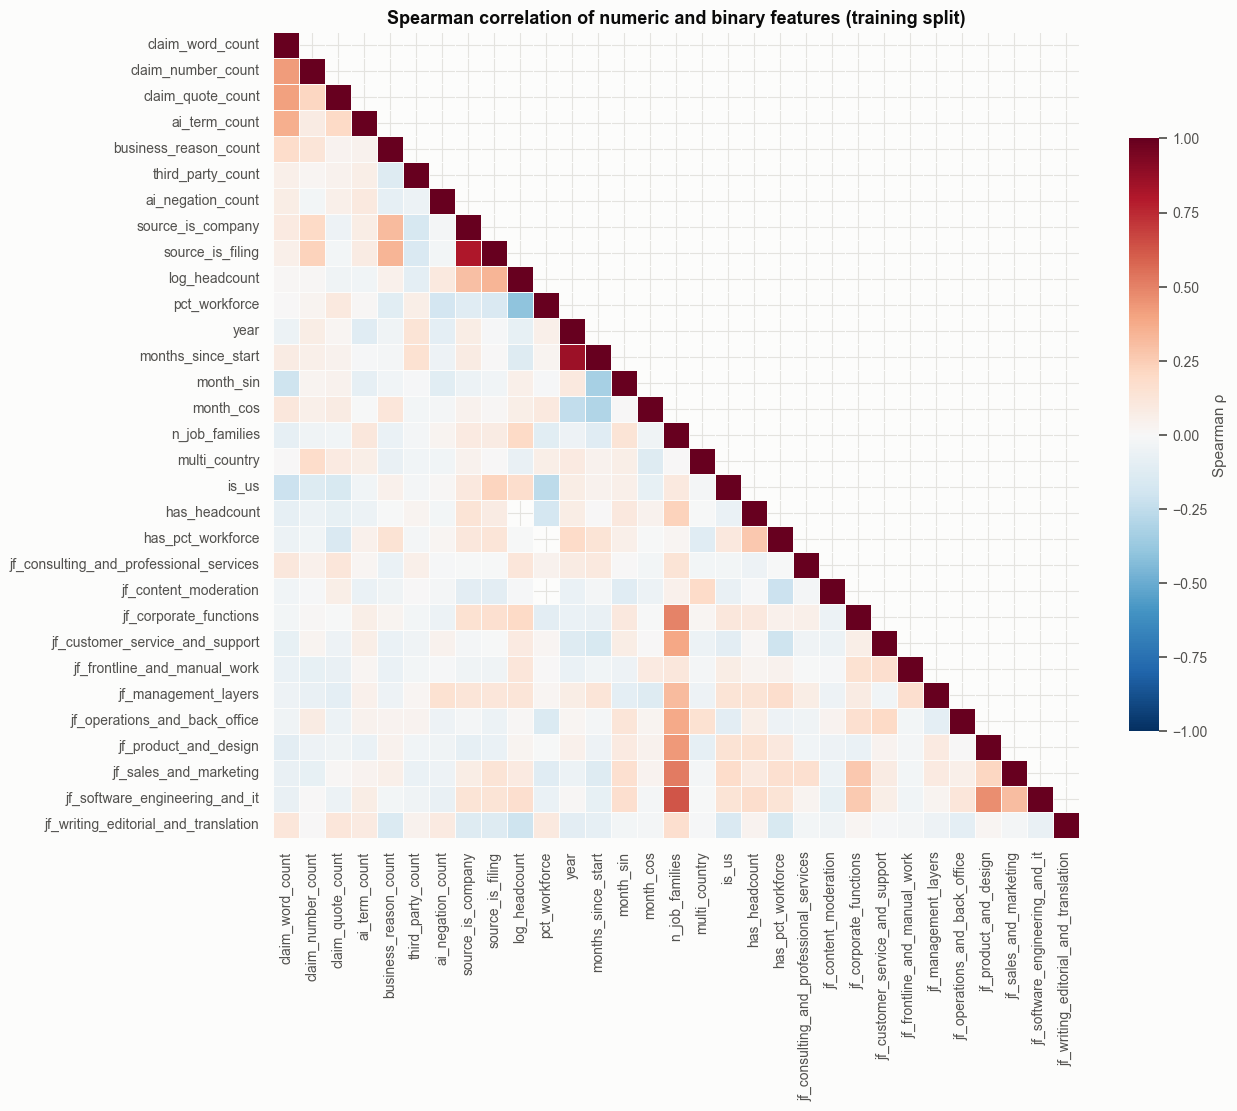

In [29]:
CANDIDATE_NUMERIC = (ENGINEERED_TEXT_NUMERIC + ENGINEERED_TEXT_BINARY
                     + ["log_headcount", "pct_workforce", "year", "months_since_start", "month_sin", "month_cos",
                        "n_job_families", "multi_country", "is_us", "has_headcount", "has_pct_workforce"] + JF_COLS)
rho = train_df[CANDIDATE_NUMERIC].corr(method="spearman")

# Greedy pruning in priority order (list order = priority)
REDUNDANCY_THRESHOLD = 0.85
kept, dropped = [], {}
for col in CANDIDATE_NUMERIC:
    partners = [k for k in kept if abs(rho.loc[col, k]) > REDUNDANCY_THRESHOLD]
    if partners:
        dropped[col] = f"|rho|={abs(rho.loc[col, partners[0]]):.2f} with {partners[0]}"
    else:
        kept.append(col)
print("Dropped as redundant:", dropped if dropped else "none")

fig, ax = plt.subplots(figsize=(13, 11))
mask_upper = np.triu(np.ones_like(rho, dtype=bool), k=1)
sns.heatmap(rho, mask=mask_upper, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, linecolor=SURFACE, cbar_kws={"label": "Spearman ρ", "shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation of numeric and binary features (training split)")
savefig(fig, "fig06_spearman_correlation")

**Decision.** The only pairs above the 0.85 threshold are the redundant ones listed above (typically `months_since_start` with `year`, which describe the same time trend). The dropped column is removed from the final specification; all other features are kept.

### 7.4 Feature relevance (training split only)
- **Mutual information** (MI) between each numeric/binary feature and the label (median-imputed; binary features marked discrete).
- **Cramér's V** for the categorical context features.
- **One-vs-rest χ²** on the TF-IDF matrix: the n-grams most associated with each class.

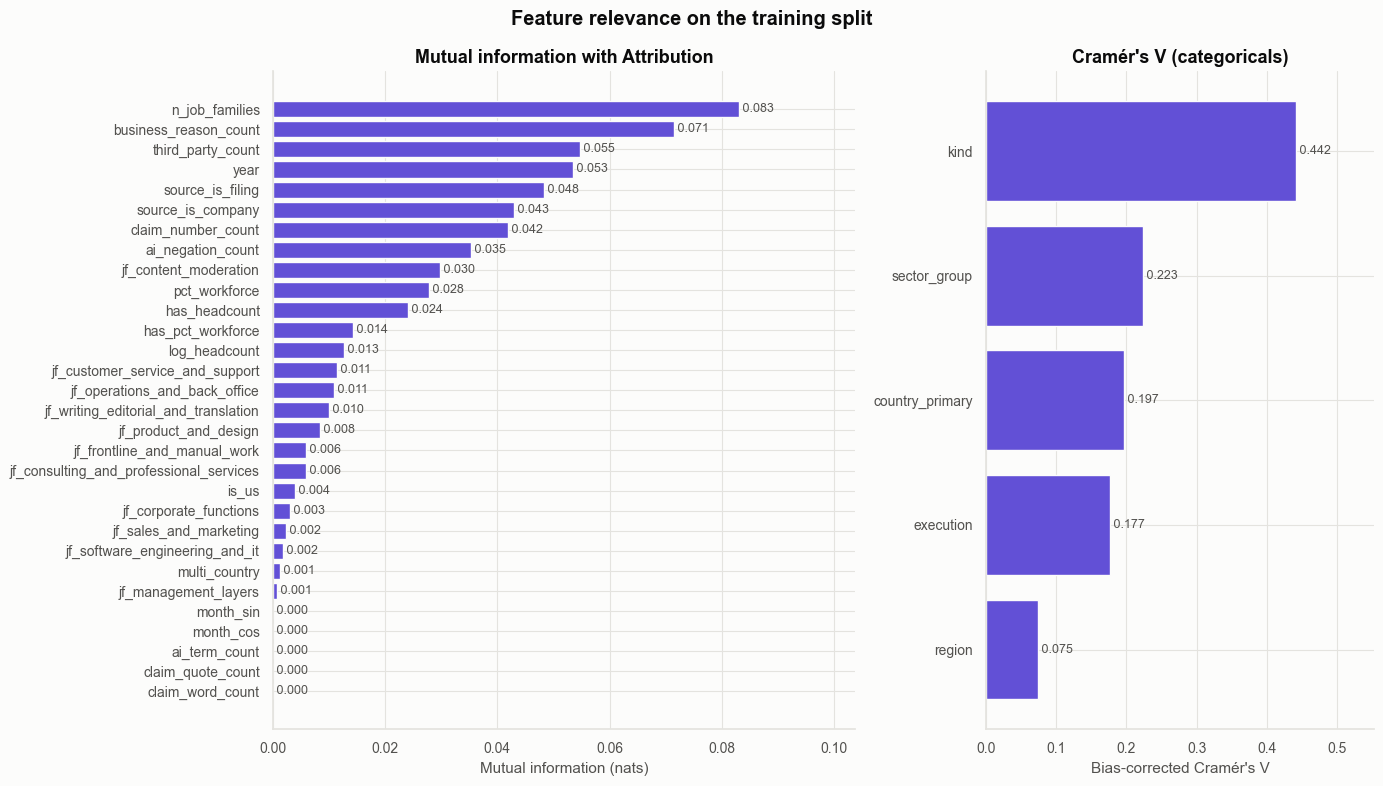

,mutual_info
n_job_families,0.0830
business_reason_count,0.0715
third_party_count,0.0548
year,0.0535
source_is_filing,0.0483
source_is_company,0.0429
claim_number_count,0.0419
ai_negation_count,0.0353
jf_content_moderation,0.0297
pct_workforce,0.0277


,cramers_v
kind,0.442
sector_group,0.223
country_primary,0.197
execution,0.177
region,0.075


In [30]:
num_feats = [c for c in CANDIDATE_NUMERIC if c not in dropped]
X_num = SimpleImputer(strategy="median").fit_transform(train_df[num_feats])
is_discrete = np.array([set(np.unique(train_df[c].dropna())) <= {0, 1} for c in num_feats])
mi = pd.Series(mutual_info_classif(X_num, y_train, discrete_features=is_discrete,
                                   random_state=RANDOM_STATE), index=num_feats).sort_values()

cat_feats = BASE_SPEC["context_categorical"]
cv_train = pd.Series({c: cramers_v(train_df[c], y_train) for c in cat_feats}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [3, 2]})
axes[0].barh(mi.index, mi.values, color=ACCENT, edgecolor=SURFACE)
axes[0].set_title("Mutual information with Attribution")
axes[0].set_xlabel("Mutual information (nats)")
axes[1].barh(cv_train.index, cv_train.values, color=ACCENT, edgecolor=SURFACE)
axes[1].set_title("Cramér's V (categoricals)")
axes[1].set_xlabel("Bias-corrected Cramér's V")
for ax, s in ((axes[0], mi), (axes[1], cv_train)):
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=9, color=TEXT2)
    ax.set_xlim(0, s.max() * 1.25 + 1e-9)
fig.suptitle("Feature relevance on the training split", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig07_feature_relevance_mi_cramers")
display(mi.sort_values(ascending=False).round(4).rename("mutual_info").to_frame().head(12))
display(cv_train.sort_values(ascending=False).round(3).rename("cramers_v").to_frame())

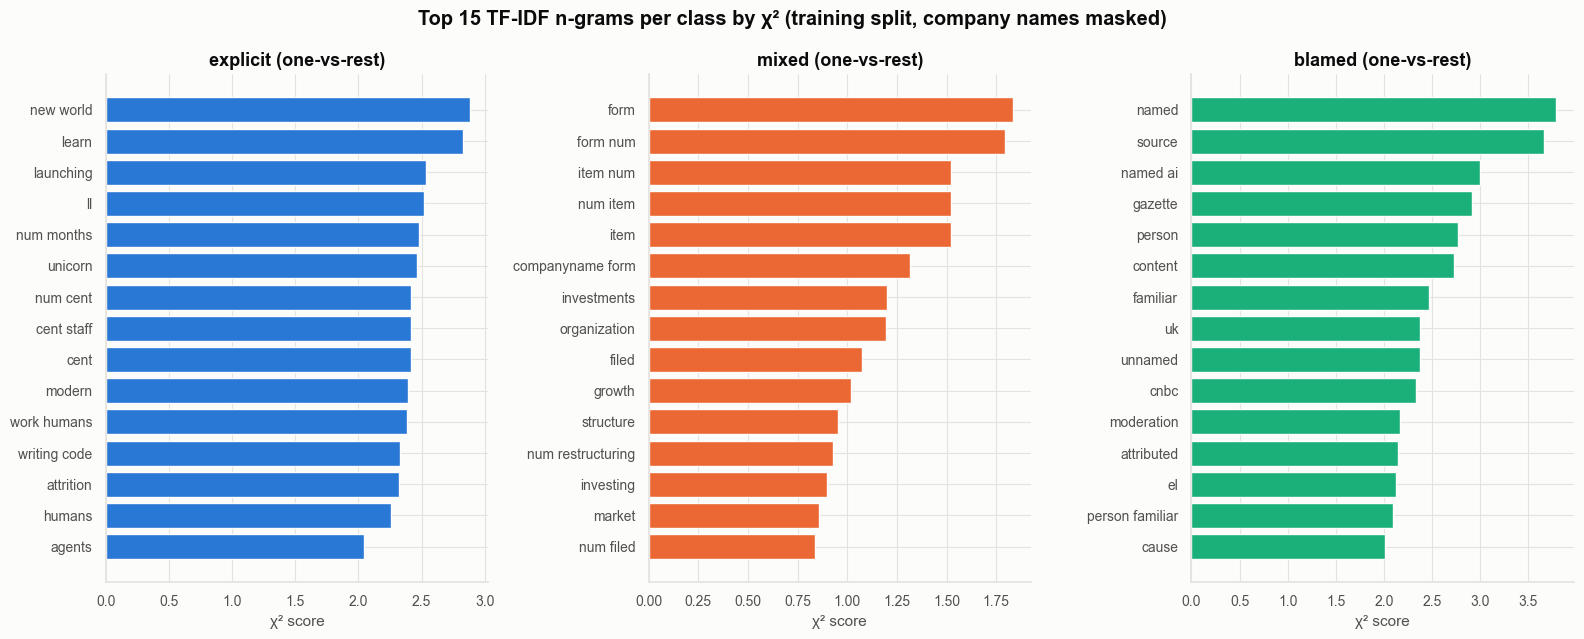

,company terms in top-15 (unmasked),company terms in top-15 (masked)
explicit,2,0
mixed,0,0
blamed,4,0


Unmasked company terms: {'explicit': ['klarna', 'gizmodo'], 'mixed': [], 'blamed': ['tiktok', 'microsoft', 'google', 'zomato']}
Masked company terms  : {'explicit': [], 'mixed': [], 'blamed': []}


In [31]:
# One-vs-rest chi-squared on train-only TF-IDF: top n-grams positively associated with each class
TOP_K = 15

def chi2_top_terms(texts, y, k=TOP_K):
    """Fit TF-IDF on the given (training) texts; return the top-k positively associated n-grams per class."""
    vec = TfidfVectorizer(ngram_range=(1, 2), stop_words="english", min_df=2, sublinear_tf=True)
    X = vec.fit_transform(texts)
    vocab = np.array(vec.get_feature_names_out())
    out = {}
    for cls in CLASSES:
        in_cls = y.eq(cls).to_numpy(dtype=bool)
        scores = np.nan_to_num(chi2(X, in_cls)[0])
        # keep only terms that are MORE frequent inside the class than outside it
        mean_in = np.asarray(X[in_cls].mean(axis=0)).ravel()
        mean_out = np.asarray(X[~in_cls].mean(axis=0)).ravel()
        scores = np.where(mean_in > mean_out, scores, 0)
        top = np.argsort(scores)[::-1][:k]
        out[cls] = pd.Series(scores[top], index=vocab[top])
    return out

chi_top = chi2_top_terms(train_df["text_clean"], y_train)

fig, axes = plt.subplots(1, 3, figsize=(16, 6.5))
for ax, cls in zip(axes, CLASSES):
    s = chi_top[cls].iloc[::-1]
    ax.barh(s.index, s.values, color=CLASS_COLORS[cls], edgecolor=SURFACE)
    ax.set_title(f"{cls} (one-vs-rest)", color=TEXT)
    ax.set_xlabel("χ² score")
fig.suptitle(f"Top {TOP_K} TF-IDF n-grams per class by χ² (training split, company names masked)", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig08_chi2_top_ngrams")

# Why masking matters: repeat the same analysis on the UNMASKED text and count company-name terms
alias_clean = {clean_text(a) for al in df["company_aliases"] for a in al}
single_word_aliases = {a for a in alias_clean if " " not in a and len(a) > 2 and a != "num"}

def company_terms(top):
    """Top terms that equal a company alias or contain a single-word company alias."""
    return {cls: [t for t in s.index if t in alias_clean or set(t.split()) & single_word_aliases]
            for cls, s in top.items()}

unmasked_text = (train_df["claim"].map(clean_text) + " " + train_df["source_title"].map(clean_text)).str.strip()
chi_top_unmasked = chi2_top_terms(unmasked_text, y_train)
masking_check = pd.DataFrame({
    "company terms in top-15 (unmasked)": {c: len(v) for c, v in company_terms(chi_top_unmasked).items()},
    "company terms in top-15 (masked)": {c: len(v) for c, v in company_terms(chi_top).items()},
}).reindex(CLASSES)
display(masking_check)
print("Unmasked company terms:", company_terms(chi_top_unmasked))
print("Masked company terms  :", company_terms(chi_top))

**What we see.**
- **Masking works.** On the *unmasked* text, 6 of the top-45 terms are company names (*klarna*, *gizmodo* for explicit; *tiktok*, *microsoft*, *google*, *zomato* for blamed). These are companies with several same-label events, so the model would be learning *who* rather than *what was said*. After masking there are **none**.
- **blamed:** *named / named ai / cause / attributed*, *source / unnamed / person familiar*, outlet names (*cnbc*, *gazette*) and *content moderation*. This is the language of **third-party attribution**: someone other than the employer makes the AI link. Some of these terms (*named ai*, *cause*) partly come from the register's verdict phrases flagged in §6.5.
- **explicit:** *work humans, writing code, agents, learn, new world, launching*. The employer talks directly about AI doing the work.
- **mixed:** SEC-filing vocabulary (*form, item num, filed*) and business language (*restructuring, investments, organization, growth, market*). The AI mention sits inside a formal disclosure of several reasons.

### 7.5 Final feature lists for Part 2

In [32]:
def keep(cols):
    """Remove columns dropped by the redundancy check."""
    return [c for c in cols if c not in dropped]

FINAL_SPEC = {
    "text": "text_clean",
    "text_numeric": keep(ENGINEERED_TEXT_NUMERIC),
    "text_binary": keep(ENGINEERED_TEXT_BINARY),
    "context_categorical": BASE_SPEC["context_categorical"],
    "context_numeric": keep(["log_headcount", "pct_workforce", "year", "months_since_start",
                             "month_sin", "month_cos", "n_job_families"]),
    "context_binary": keep(["multi_country", "is_us", "has_headcount", "has_pct_workforce"] + JF_COLS),
}
EXPERIMENTS = {
    "exp1_text_only": {"use_text": True, "use_context": False,
                       "columns": [FINAL_SPEC["text"]] + FINAL_SPEC["text_numeric"] + FINAL_SPEC["text_binary"]},
    "exp2_context_only": {"use_text": False, "use_context": True,
                          "columns": FINAL_SPEC["context_categorical"] + FINAL_SPEC["context_numeric"]
                          + FINAL_SPEC["context_binary"]},
}
EXPERIMENTS["exp3_combined"] = {"use_text": True, "use_context": True,
                                "columns": EXPERIMENTS["exp1_text_only"]["columns"]
                                + EXPERIMENTS["exp2_context_only"]["columns"]}
for name, e in EXPERIMENTS.items():
    print(f"{name}: {len(e['columns'])} input columns -> {e['columns']}\n")

display(config_shapes(FINAL_SPEC))

exp1_text_only: 10 input columns -> ['text_clean', 'claim_word_count', 'claim_number_count', 'claim_quote_count', 'ai_term_count', 'business_reason_count', 'third_party_count', 'ai_negation_count', 'source_is_company', 'source_is_filing']

exp2_context_only: 26 input columns -> ['sector_group', 'region', 'country_primary', 'kind', 'execution', 'log_headcount', 'pct_workforce', 'year', 'month_sin', 'month_cos', 'n_job_families', 'multi_country', 'is_us', 'has_headcount', 'has_pct_workforce', 'jf_consulting_and_professional_services', 'jf_content_moderation', 'jf_corporate_functions', 'jf_customer_service_and_support', 'jf_frontline_and_manual_work', 'jf_management_layers', 'jf_operations_and_back_office', 'jf_product_and_design', 'jf_sales_and_marketing', 'jf_software_engineering_and_it', 'jf_writing_editorial_and_translation']

exp3_combined: 36 input columns -> ['text_clean', 'claim_word_count', 'claim_number_count', 'claim_quote_count', 'ai_term_count', 'business_reason_count', 'thir

,train shape,test shape,sparse
config,,,
Exp 1: text only,"(245, 2107)","(75, 2107)",True
Exp 2: context only,"(245, 62)","(75, 62)",False
Exp 3: combined,"(245, 2169)","(75, 2169)",True


**Decision.** Experiment 1 uses the TF-IDF text plus the engineered *text* statistics. Experiment 2 uses only *context* (categoricals, numerics, flags, job families). Experiment 3 uses both. No χ²/MI-based filtering is applied here: with ~250 training rows, feature selection should happen **inside** Part 2's cross-validation folds (e.g. `SelectKBest` in the pipeline), otherwise the selection itself leaks. The rankings above are used for interpretation (RQ1).

## 8. Exploratory data analysis
All figures describe the full cleaned dataset (EDA describes the data and does not fit anything a model uses). Each figure is followed by an interpretation.

### 8.1 Class distribution and the majority baseline

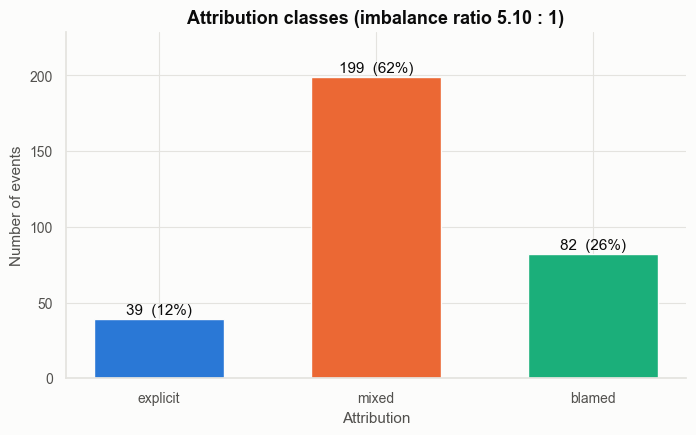

Imbalance ratio (majority/minority) = 5.10


,accuracy,macro_F1,balanced_accuracy
full data,0.622,0.256,0.333
group test split,0.600,0.250,0.333


In [33]:
counts = df["attribution"].value_counts().reindex(CLASSES)
imbalance_ratio = counts.max() / counts.min()

# Majority-class reference: always predict 'mixed'. A constant prediction, not a trained model.
def majority_reference(y):
    pred = np.full(len(y), "mixed")
    return {"accuracy": accuracy_score(y, pred),
            "macro_F1": f1_score(y, pred, average="macro", labels=CLASSES, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y, pred)}

baseline = pd.DataFrame({"full data": majority_reference(df["attribution"]),
                         "group test split": majority_reference(y_test)}).T.round(3)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index, counts.values, color=CLASS_PALETTE, edgecolor=SURFACE, width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 3, f"{v}  ({v / len(df):.0%})", ha="center", color=TEXT, fontsize=11)
ax.set_title(f"Attribution classes (imbalance ratio {imbalance_ratio:.2f} : 1)")
ax.set_xlabel("Attribution")
ax.set_ylabel("Number of events")
ax.set_ylim(0, counts.max() * 1.15)
savefig(fig, "fig09_class_distribution")
print(f"Imbalance ratio (majority/minority) = {imbalance_ratio:.2f}")
display(baseline)

**Interpretation.** `mixed` makes up about 62 % of events and `explicit` only about 12 % (an imbalance ratio of about 5 : 1). Always predicting *mixed* gives about 62 % **accuracy** but a **macro-F1 of only about 0.26** and a balanced accuracy of 0.33. This is why **macro-F1 is the primary metric**: accuracy would reward ignoring the minority classes. Any Part 2 model must clearly beat a macro-F1 of 0.26.

### 8.2 Events over time and the attribution mix

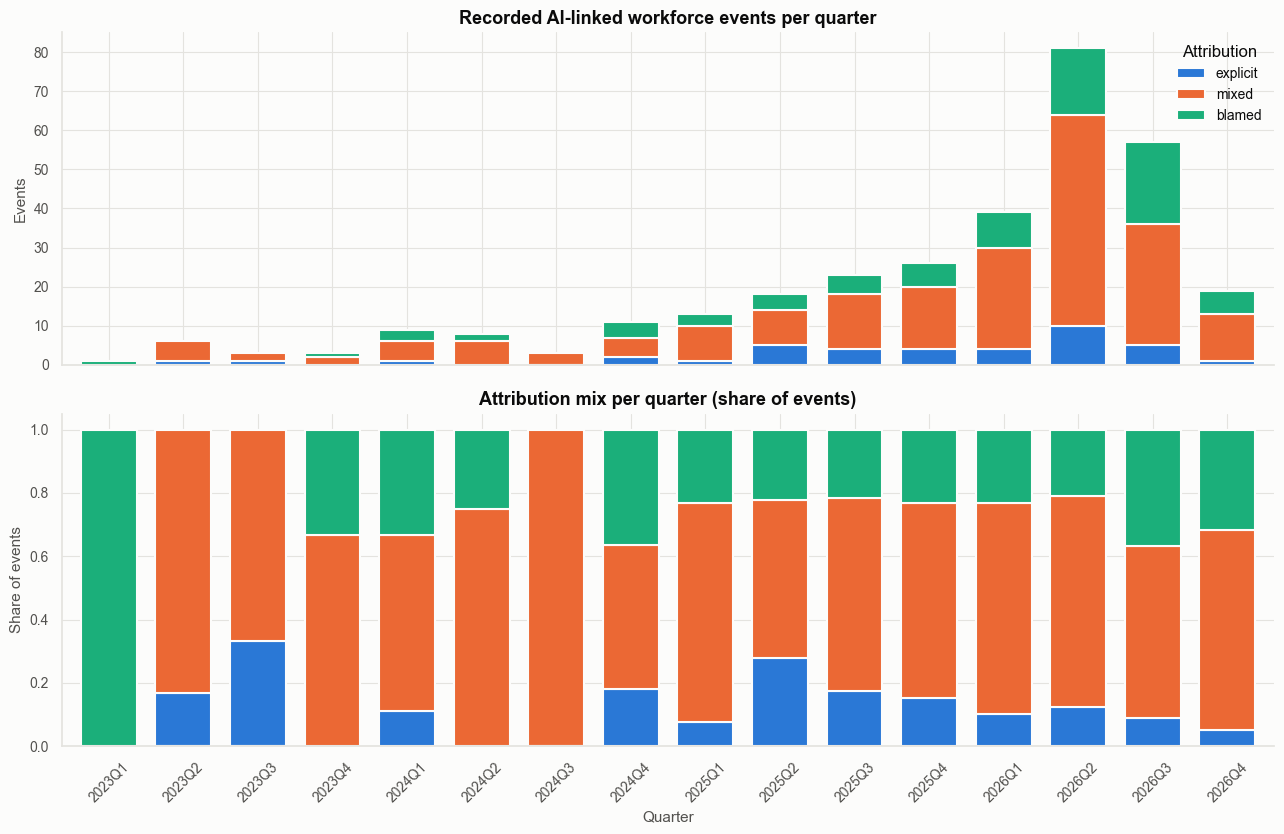

attribution,explicit,mixed,blamed,All
year,,,,
2023,2,9,2,13
2024,3,19,9,31
2025,14,48,18,80
2026,20,123,53,196
All,39,199,82,320


In [34]:
quarters = pd.period_range(df["date"].min(), df["date"].max(), freq="Q").astype(str).str.replace("Q", "Q")
qt = pd.crosstab(df["year_quarter"], df["attribution"]).reindex(columns=CLASSES, fill_value=0)
qt = qt.reindex(sorted(set(qt.index) | set(quarters)), fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True)
stacked_class_bars(qt, axes[0], horizontal=False)
axes[0].set_title("Recorded AI-linked workforce events per quarter")
axes[0].set_ylabel("Events")
share = qt.div(qt.sum(axis=1).replace(0, np.nan), axis=0)
stacked_class_bars(share.fillna(0), axes[1], horizontal=False)
axes[1].set_title("Attribution mix per quarter (share of events)")
axes[1].set_ylabel("Share of events")
axes[1].set_xlabel("Quarter")
axes[1].get_legend().remove()
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
savefig(fig, "fig10_events_over_time")
display(pd.crosstab(df["year"], df["attribution"], margins=True).reindex(columns=CLASSES + ["All"]))

**Interpretation.** Coverage is very uneven over time: 2023 has 13 events and 2024 has 31, while 2025–2026 account for **86 %** of all records, peaking in 2026 Q2 (81 events). 2026 Q4 only runs to 22 October. This reflects both a real increase in AI-linked announcements and the register's own collection effort. From 2025 onwards the mix is fairly stable (mostly 60–70 % mixed). The early quarters swing widely only because they contain a handful of events. The date features may pick up *collection* patterns as well as real trends. The chronological holdout (`chrono_split`, events from 2026-07-15) has only **3 explicit events**, so in Part 2 it can only be a rough robustness check.

### 8.3 Sector groups

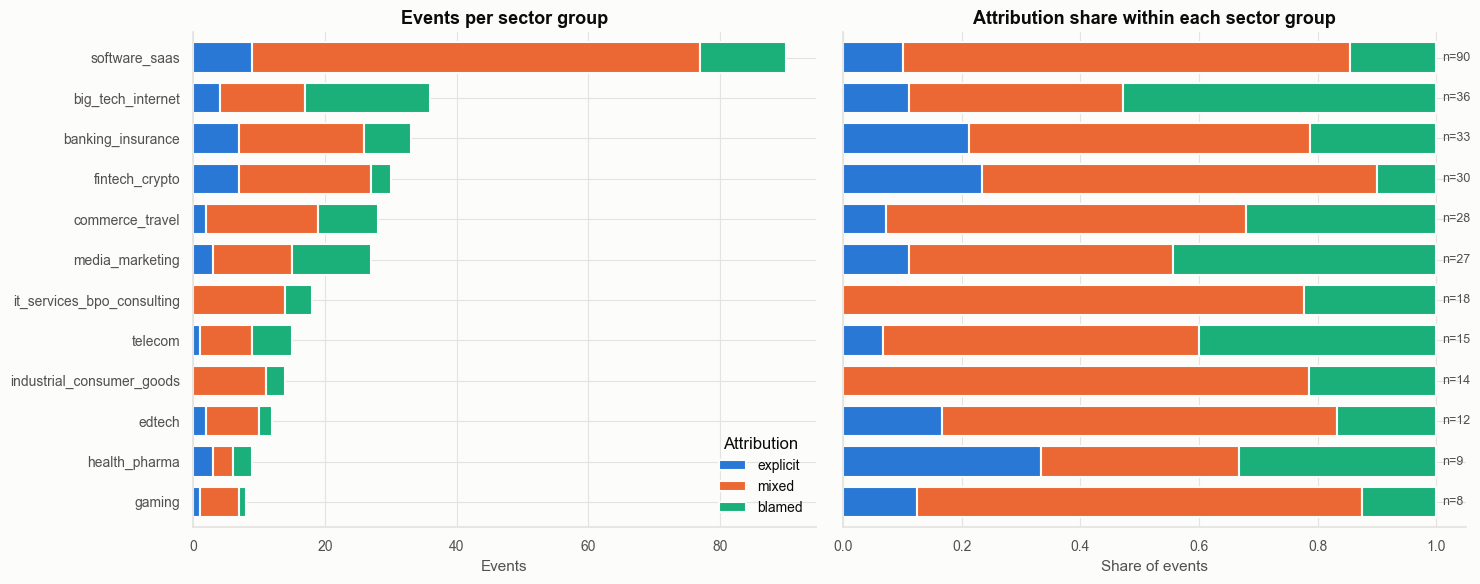

In [35]:
sg = pd.crosstab(df["sector_group"], df["attribution"]).reindex(columns=CLASSES)
sg = sg.loc[sg.sum(axis=1).sort_values().index]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
stacked_class_bars(sg, axes[0])
axes[0].set_title("Events per sector group")
axes[0].set_xlabel("Events")
axes[0].set_ylabel("")
stacked_class_bars(sg, axes[1], normalize=True)
axes[1].set_title("Attribution share within each sector group")
axes[1].set_xlabel("Share of events")
axes[1].get_legend().remove()
for i, n in enumerate(sg.sum(axis=1)):
    axes[1].text(1.01, i, f"n={n}", va="center", fontsize=9, color=TEXT2)
fig.tight_layout()
savefig(fig, "fig11_sector_groups")

**Interpretation.** Software/SaaS is the largest group (90 events), followed by big tech (36), banking/insurance (33) and fintech/crypto (30). The attribution mix differs clearly by sector:
- **Big tech / internet** is **53 % blamed**, the highest of any group: large, closely watched firms whose cuts the press links to AI even when the firm does not. Media/marketing (44 %) and telecom (40 %) are also blamed-heavy.
- **Software/SaaS** is about 76 % mixed. **IT services** and **industrial/consumer goods** have **no explicit events at all**.
- **Banking/insurance** (21 %) and **fintech/crypto** (23 %) have about twice the overall explicit rate of 12 %.

Sector is therefore a promising context feature (RQ2, train-split Cramér's V ≈ 0.22), but several groups have fewer than 15 events, so its estimates will be noisy.

### 8.4 Countries and regions

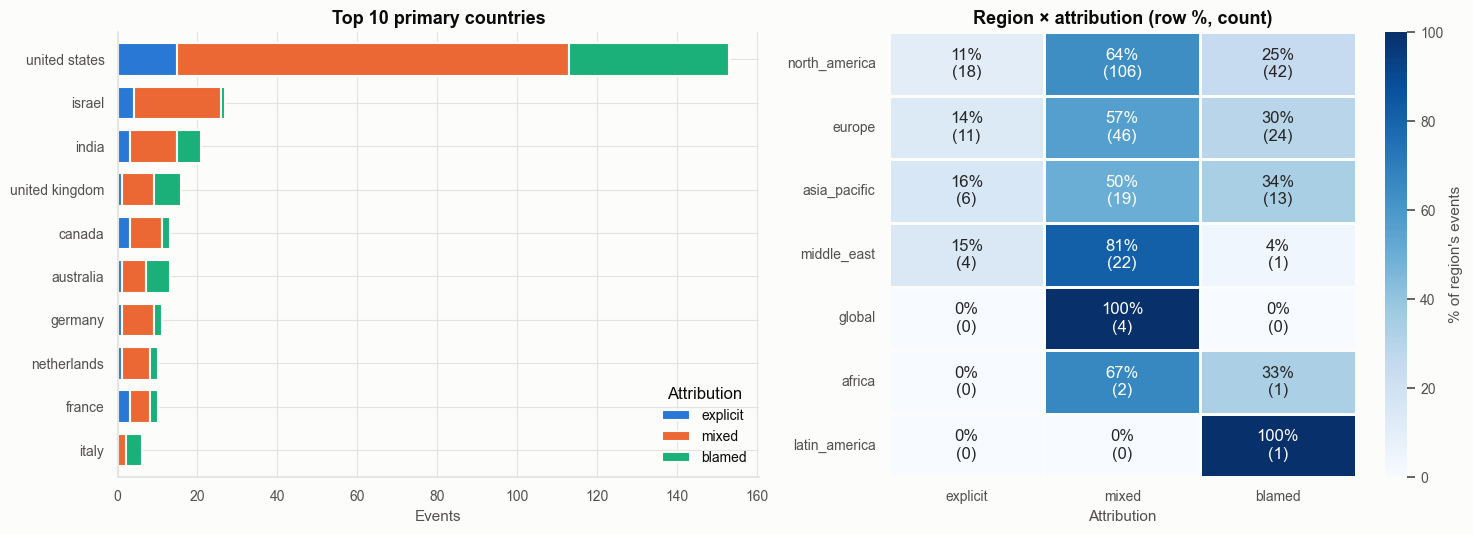

In [36]:
top_c = df["country_primary"].value_counts().head(10).index
cc = pd.crosstab(df.loc[df["country_primary"].isin(top_c), "country_primary"],
                 df["attribution"]).reindex(columns=CLASSES, fill_value=0)
cc = cc.loc[cc.sum(axis=1).sort_values().index]
rc = pd.crosstab(df["region"], df["attribution"]).reindex(columns=CLASSES, fill_value=0)
rc = rc.loc[rc.sum(axis=1).sort_values(ascending=False).index]
rc_pct = rc.div(rc.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
stacked_class_bars(cc, axes[0])
axes[0].set_title("Top 10 primary countries")
axes[0].set_xlabel("Events")
axes[0].set_ylabel("")
annot = rc_pct.round(0).astype(int).astype(str) + "%\n(" + rc.astype(str) + ")"
sns.heatmap(rc_pct, annot=annot, fmt="", cmap=SEQ_CMAP, vmin=0, vmax=100, linewidths=1, linecolor=SURFACE,
            cbar_kws={"label": "% of region's events"}, ax=axes[1])
axes[1].set_title("Region × attribution (row %, count)")
axes[1].set_xlabel("Attribution")
axes[1].set_ylabel("")
fig.tight_layout()
savefig(fig, "fig12_countries_regions")

**Interpretation.** The United States dominates (48 % of events have a US primary country), followed by Israel (27), India (21) and the UK (16). North America (25 % blamed), Europe (30 %) and Asia-Pacific (34 %) have similar mixes. The one clear exception is **Israel / `middle_east`: 81 % mixed and only 1 blamed event out of 27**. A plausible reason is the source mix: *calcalist ctech* (an Israeli business outlet) is among the most frequent mixed bigrams (§8.8), so much of this coverage relays the company's own explanation. Global, African and Latin American groups have 1–4 events each, so their shares mean nothing. Overall region is a **weak** signal (Cramér's V ≈ 0.08); `country_primary` (V ≈ 0.20) carries more, mainly through Israel.

### 8.5 Event kind, execution status and evidence tier

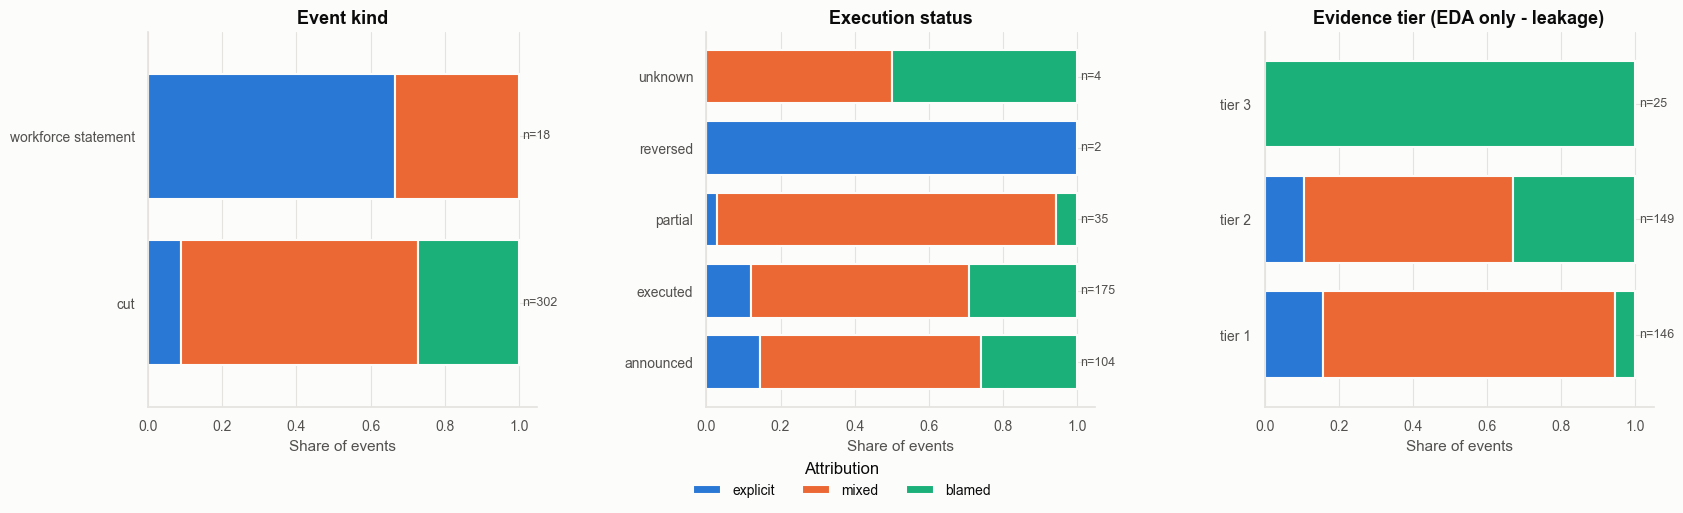

In [37]:
panels = [("kind", "Event kind"), ("execution", "Execution status"), ("evidence_tier", "Evidence tier (EDA only - leakage)")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (col, title) in zip(axes, panels):
    ct = pd.crosstab(df[col], df["attribution"]).reindex(columns=CLASSES, fill_value=0)
    stacked_class_bars(ct, ax, normalize=True)
    for i, n in enumerate(ct.sum(axis=1)):
        ax.text(1.01, i, f"n={n}", va="center", fontsize=9, color=TEXT2)
    ax.set_title(title)
    ax.set_xlabel("Share of events")
    ax.set_ylabel("")
    ax.get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Attribution", loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout(w_pad=4)
savefig(fig, "fig13_kind_execution_tier")

**Interpretation.**
- **Kind:** the 18 *workforce statements* (an employer talking about AI and headcount without a specific cut) are 67 % *explicit* and **never blamed**, while the 302 cuts have only 9 % explicit. A strong, legitimate signal, and the strongest categorical feature (train Cramér's V ≈ 0.44), but it only helps for a small subset of events.
- **Execution:** *partial* events (n = 35) are 91 % *mixed*. The 2 *reversed* events are both explicit, and the 4 *unknown* events are mixed or blamed. *Executed* and *announced* (279 events) show the overall class mix, so execution mostly helps at the margins.
- **Evidence tier** (shown for understanding only): Tier 3 consists entirely of *blamed* events, which is why it is excluded from the features.

### 8.6 Headcount, % of workforce and claim length by class
Box plots with the individual events overlaid, plus a **Kruskal–Wallis** test (a non-parametric test of whether the class distributions differ).

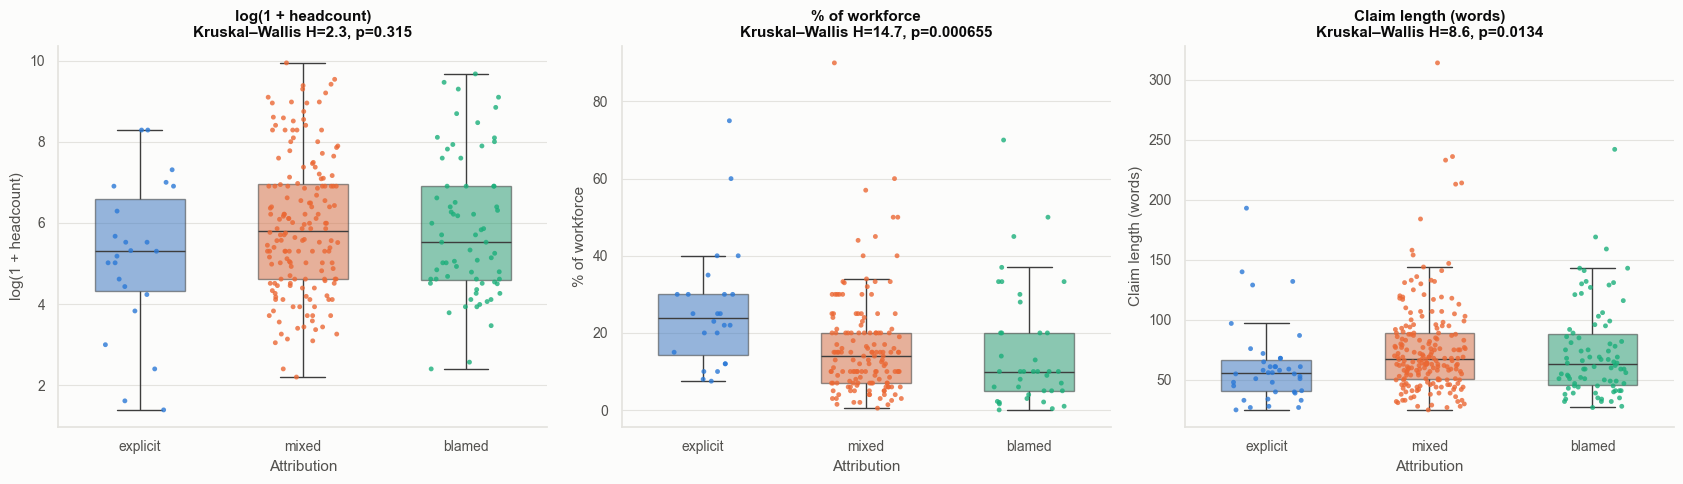

,H,p_value,median_explicit,median_mixed,median_blamed,n_explicit,n_mixed,n_blamed
feature,,,,,,,,
log_headcount,2.31,0.314969,5.3,5.81,5.53,23,166,68
pct_workforce,14.66,0.000655,24.0,14.00,10.00,24,147,39
claim_word_count,8.63,0.013372,56.0,67.00,63.00,39,199,82


In [38]:
num_views = [("log_headcount", "log(1 + headcount)"), ("pct_workforce", "% of workforce"),
             ("claim_word_count", "Claim length (words)")]
kw_rows = []
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (col, label) in zip(axes, num_views):
    groups = [df.loc[df["attribution"].eq(c), col].dropna() for c in CLASSES]
    h, p = kruskal(*groups)
    kw_rows.append({"feature": col, "H": round(h, 2), "p_value": p,
                    **{f"median_{c}": round(g.median(), 2) for c, g in zip(CLASSES, groups)},
                    **{f"n_{c}": len(g) for c, g in zip(CLASSES, groups)}})
    sns.boxplot(data=df, x="attribution", y=col, hue="attribution", order=CLASSES, palette=CLASS_COLORS,
                legend=False, showfliers=False, width=0.55, boxprops={"alpha": 0.55}, ax=ax)
    sns.stripplot(data=df, x="attribution", y=col, hue="attribution", order=CLASSES, palette=CLASS_COLORS,
                  legend=False, size=3.5, jitter=0.22, alpha=0.8, ax=ax)
    ax.set_title(f"{label}\nKruskal–Wallis H={h:.1f}, p={p:.3g}", fontsize=11)
    ax.set_xlabel("Attribution")
    ax.set_ylabel(label)
fig.tight_layout()
savefig(fig, "fig14_numeric_by_class")
kw_tbl = pd.DataFrame(kw_rows).set_index("feature")
kw_tbl

**Interpretation.**
- **Event size does not differ** between classes (headcount: H = 2.3, p = 0.31; medians about 200–330 roles). AI is linked to small and large cuts alike.
- **% of workforce does differ** (H = 14.7, p < 0.001): explicit events cut a much larger *share* of staff (median 24 %) than mixed (14 %) or blamed (10 %) ones. This fits smaller firms announcing that AI replaces a large part of a team. Only 24 explicit events have a share, so this is suggestive.
- **Claim length differs mildly** (H = 8.6, p = 0.013): explicit claims are the shortest (median 56 words vs 67 mixed and 63 blamed). An explicit statement needs less context to document.

Overall, numeric context is a supporting signal, not a strong separator.

### 8.7 Engineered text features by class
Share of events in each class whose claim contains at least one occurrence of each signal.

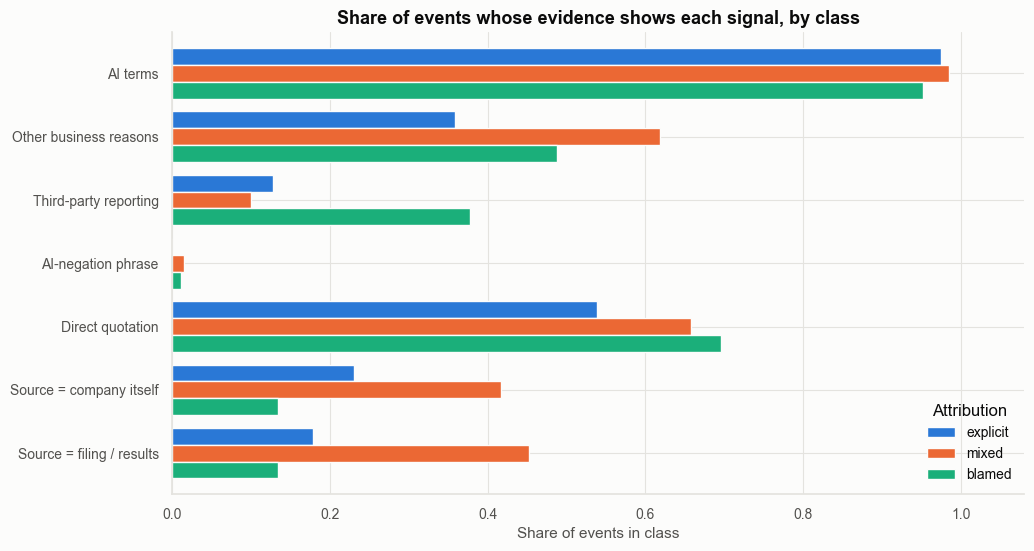

attribution,explicit,mixed,blamed
AI terms,97.4,98.5,95.1
Other business reasons,35.9,61.8,48.8
Third-party reporting,12.8,10.1,37.8
AI-negation phrase,0.0,1.5,1.2
Direct quotation,53.8,65.8,69.5
Source = company itself,23.1,41.7,13.4
Source = filing / results,17.9,45.2,13.4


attribution,explicit,mixed,blamed
ai_term_count,2.03,2.00,2.05
business_reason_count,0.49,1.30,0.78
third_party_count,0.15,0.13,0.55
ai_negation_count,0.00,0.02,0.01
claim_quote_count,1.15,1.42,1.43
source_is_company,0.23,0.42,0.13
source_is_filing,0.18,0.45,0.13


In [39]:
sig_cols = ["ai_term_count", "business_reason_count", "third_party_count", "ai_negation_count",
            "claim_quote_count", "source_is_company", "source_is_filing"]
pretty = {"ai_term_count": "AI terms", "business_reason_count": "Other business reasons",
          "third_party_count": "Third-party reporting", "ai_negation_count": "AI-negation phrase",
          "claim_quote_count": "Direct quotation", "source_is_company": "Source = company itself",
          "source_is_filing": "Source = filing / results"}
presence = (df[sig_cols] > 0).groupby(df["attribution"]).mean().reindex(CLASSES).T.rename(index=pretty)

fig, ax = plt.subplots(figsize=(11, 6))
presence.plot(kind="barh", ax=ax, color=CLASS_PALETTE, edgecolor=SURFACE, width=0.8)
ax.invert_yaxis()
ax.set_title("Share of events whose evidence shows each signal, by class")
ax.set_xlabel("Share of events in class")
ax.set_ylabel("")
ax.set_xlim(0, 1.08)
ax.legend(title="Attribution", loc="lower right")
savefig(fig, "fig15_text_signals_by_class")
display((presence * 100).round(1))
display(df.groupby("attribution")[sig_cols].mean().reindex(CLASSES).T.round(2))

**Interpretation.** The signals match the label definitions:
- *Third-party reporting* language appears in **38 % of blamed** claims vs 13 % explicit and 10 % mixed.
- *Other business reasons* (cost, restructuring, efficiency …) appear in **62 % of mixed** claims vs 36 % explicit, which is exactly the "AI among other reasons" definition.
- First-party sources are rare for blamed events: the source is the company itself for 13 % of blamed vs 42 % of mixed, and a filing/results document for 13 % vs 45 %.
- *AI terms* appear in 95–98 % of claims in every class (each event is AI-linked by construction), so they do not separate the classes.
- The hand-written *AI-negation* pattern fires for fewer than 2 % of events, so it adds almost nothing. Explicit denials are rare in the claims.

These patterns give clear, interpretable answers for RQ1.

### 8.8 Most frequent bigrams per class
Raw frequency of bigrams in the cleaned, masked text (English stop words removed; the placeholder bigrams `companyname num` / `num num` are excluded). Unlike χ² (§7.4), this shows what each class *typically talks about*, including shared vocabulary.

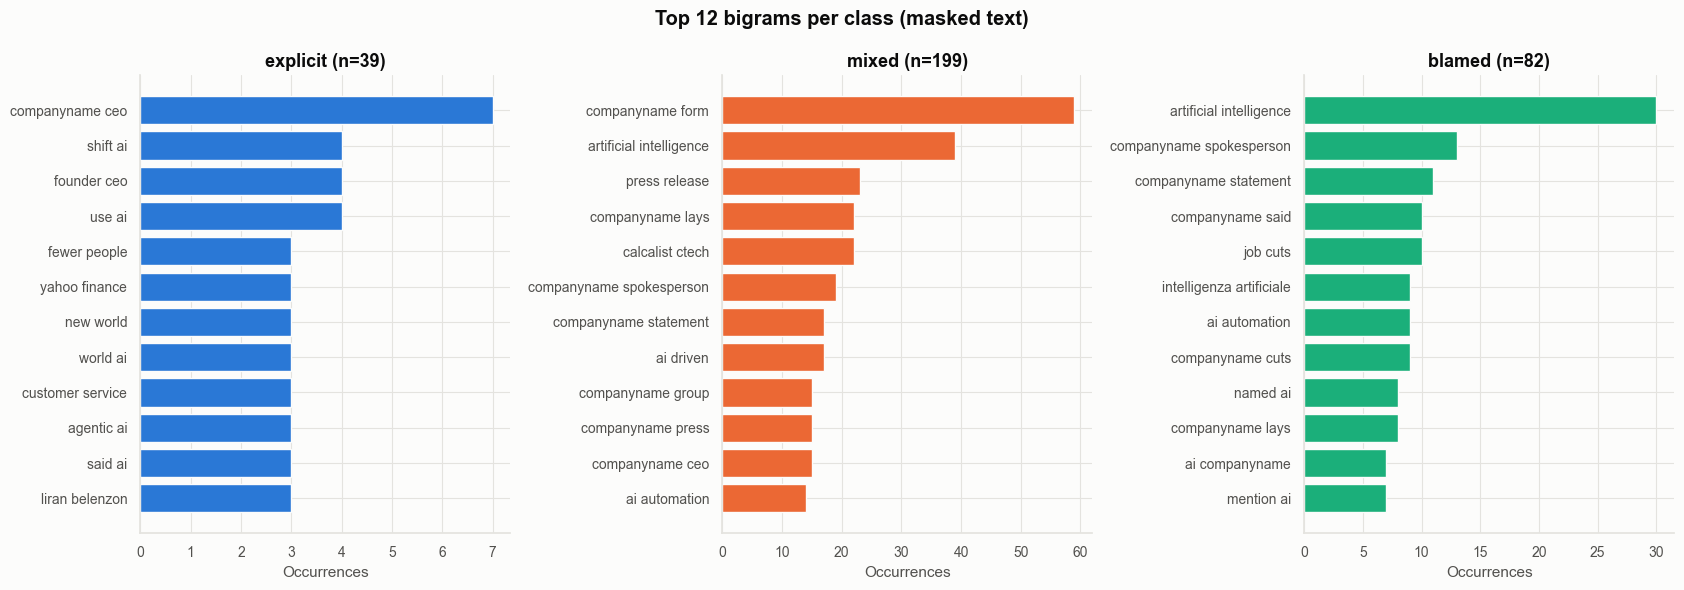

In [40]:
bi_vec = CountVectorizer(ngram_range=(2, 2), stop_words="english", min_df=2)
X_bi = bi_vec.fit_transform(df["text_clean"])
bi_vocab = np.array(bi_vec.get_feature_names_out())
noise = np.array([("num" in b.split()) or (b == "companyname companyname") for b in bi_vocab])

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, cls in zip(axes, CLASSES):
    rows = df["attribution"].eq(cls).to_numpy(dtype=bool)
    freq = np.asarray(X_bi[rows].sum(axis=0)).ravel()
    freq = np.where(noise, 0, freq)
    top = np.argsort(freq)[::-1][:12][::-1]
    ax.barh(bi_vocab[top], freq[top], color=CLASS_COLORS[cls], edgecolor=SURFACE)
    ax.set_title(f"{cls} (n={rows.sum()})")
    ax.set_xlabel("Occurrences")
fig.suptitle("Top 12 bigrams per class (masked text)", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig16_top_bigrams")

**Interpretation.**
- **explicit** is about leaders talking about AI: *companyname ceo, founder ceo, shift ai, use ai, agentic ai, fewer people, customer service*.
- **mixed** is about formal disclosures: *companyname form* (SEC Form 8-K), *press release, ai driven*. It also includes *calcalist ctech*, the Israeli outlet behind many mixed events.
- **blamed** is about the company's *response* to press stories: *companyname spokesperson, companyname statement, named ai, mention ai*. It also includes *intelligenza artificiale* (Italian press coverage).
- *artificial intelligence* and *ai automation* are frequent in several classes, which explains why a bag-of-words model will confuse neighbouring classes.
- Many bigrams contain `companyname`, which confirms that masking is active: the company stays as a concept without its identity. **Residual risk:** executive names are not masked, and one (*liran belenzon*, BenchSci's CEO, 3 events) appears in the explicit list. The company-grouped split keeps such names from carrying over between train and test.

### 8.9 Job families × class

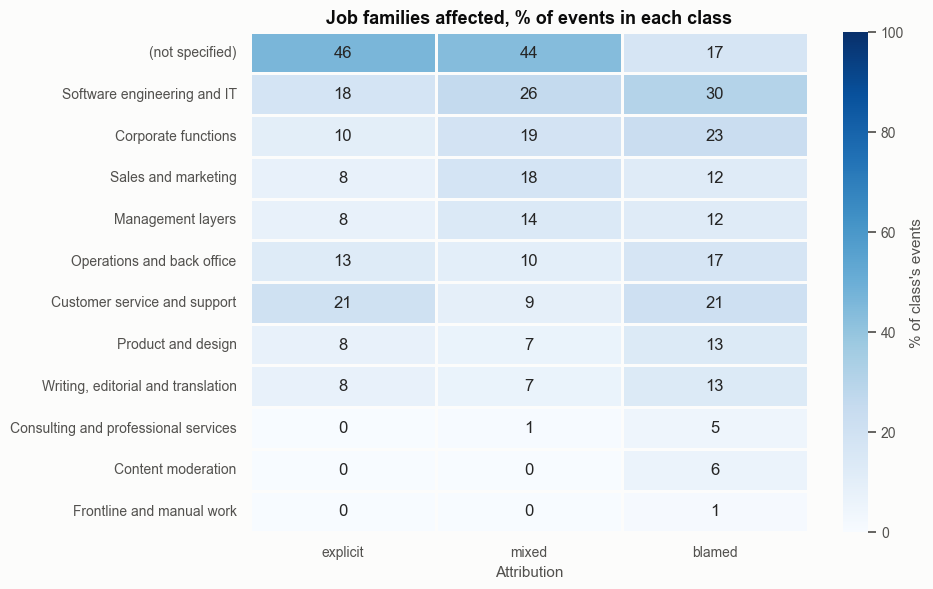

In [41]:
jf_share = df.groupby("attribution")[JF_COLS + ["n_job_families"]].mean().reindex(CLASSES).T
jf_share = jf_share.drop(index="n_job_families")
jf_share.index = [JOB_FAMILIES[JF_COLS.index(c)] for c in jf_share.index]
none_share = df["n_job_families"].eq(0).groupby(df["attribution"]).mean().reindex(CLASSES)
jf_share.loc["(not specified)"] = none_share
jf_share = jf_share.sort_values("mixed", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(jf_share * 100, annot=True, fmt=".0f", cmap=SEQ_CMAP, vmin=0, vmax=100,
            linewidths=1, linecolor=SURFACE, cbar_kws={"label": "% of class's events"}, ax=ax)
ax.set_title("Job families affected, % of events in each class")
ax.set_xlabel("Attribution")
ax.set_ylabel("")
savefig(fig, "fig17_job_families_by_class")

**Interpretation.**
- *Not specified* is common for **explicit (46 %)** and **mixed (44 %)** events but rare for **blamed (17 %)** ones. Press reports that link a cut to AI usually name the affected teams, while employers' own AI statements often stay general. This is why `n_job_families` has the highest mutual information of all numeric features.
- **Customer service and support** is hit in 21 % of explicit and blamed events but only 9 % of mixed ones. **Content moderation** appears *only* in blamed events (6 %).
- **Mixed** events more often mention sales/marketing (18 %) and management layers (14 %), which is restructuring language.

### 8.10 Repeat companies and their labels

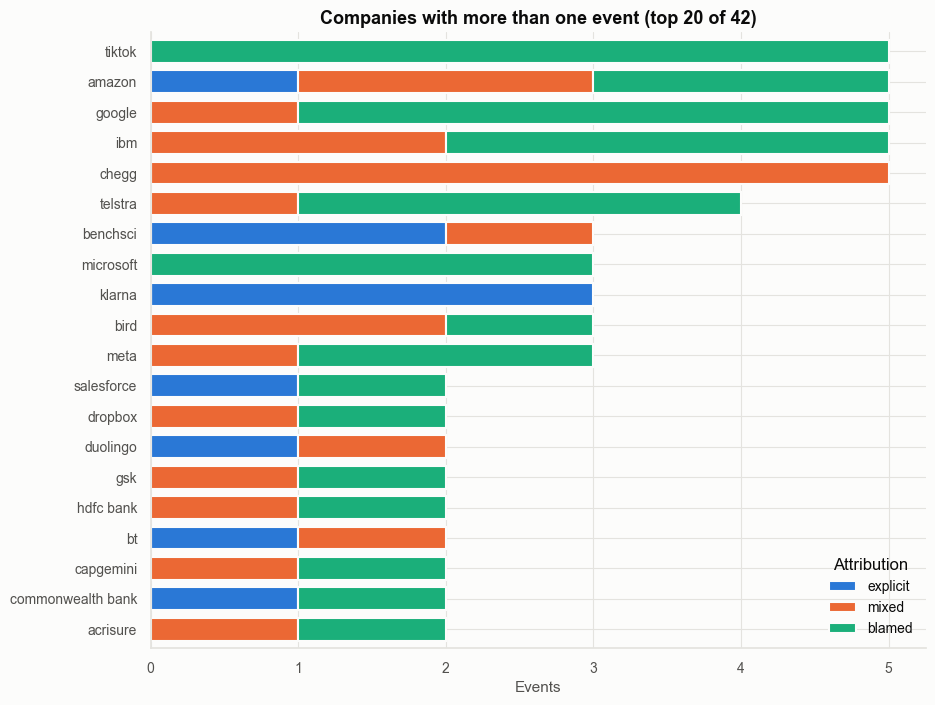

42 repeat company groups; 57% always carry the same label, 43% carry two or more different labels.


In [42]:
rep_names = rep.index[:20]
rc_tbl = (pd.crosstab(df.loc[df["company_group"].isin(rep_names), "company_group"],
                      df["attribution"]).reindex(columns=CLASSES, fill_value=0))
rc_tbl = rc_tbl.loc[rc_tbl.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 8))
stacked_class_bars(rc_tbl, ax)
ax.set_title(f"Companies with more than one event (top {len(rc_tbl)} of {len(rep)})")
ax.set_xlabel("Events")
ax.set_ylabel("")
ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
savefig(fig, "fig18_repeat_companies")
consistency = (rep["n_distinct_labels"] == 1).mean()
print(f"{len(rep)} repeat company groups; {consistency:.0%} always carry the same label, "
      f"{1 - consistency:.0%} carry two or more different labels.")

**Interpretation.** 42 company groups have more than one event (106 events, a third of the data). **57 % of them always carry the same label** (e.g. TikTok 5× blamed, Chegg 5× mixed, Klarna 3× explicit). A model that sees a company in training could therefore score well on its other events just by recognising it. This is why both the company-grouped split and the name masking matter. The other 43 % carry different labels in different events (Amazon has all three), which shows that the label describes the *event's evidence*, not the company.

## 9. Key observations and insights
The facts below are computed in this cell, so the text that follows can be checked against them.

In [43]:
# Every number quoted in the observations comes from this table
obs = {
    "rows / columns": f"{len(raw)} / {raw.shape[1]}",
    "companies / company groups": f"{df['company'].nunique()} / {df['company_group'].nunique()}",
    "class counts (explicit/mixed/blamed)": "/".join(str(int(counts[c])) for c in CLASSES),
    "imbalance ratio": round(imbalance_ratio, 2),
    "majority baseline accuracy / macro-F1 (full)": f"{baseline.loc['full data', 'accuracy']:.3f} / {baseline.loc['full data', 'macro_F1']:.3f}",
    "roles_counted missing in blamed": f"{miss_by_class.loc['roles_counted is NaN', 'blamed']:.0%}",
    "headcount missing (explicit/mixed/blamed)": " / ".join(f"{miss_by_class.loc['headcount (merged) is NaN', c]:.0%}" for c in CLASSES),
    "Cramér's V what_the_employer_said": leak_tbl.loc["what_the_employer_said", "cramers_v"],
    "Cramér's V evidence_tier": leak_tbl.loc["evidence_tier", "cramers_v"],
    "Cramér's V roles_counted is NaN": leak_tbl.loc["roles_counted is NaN", "cramers_v"],
    "Cramér's V headcount (merged) is NaN": leak_tbl.loc["headcount (merged) is NaN", "cramers_v"],
    "Cramér's V kind / sector_group / region": f"{leak_tbl.loc['kind', 'cramers_v']} / {leak_tbl.loc['sector_group', 'cramers_v']} / {leak_tbl.loc['region', 'cramers_v']}",
    "repeat company groups (events)": f"{len(rep)} ({int(rep['events'].sum())})",
    "repeat groups with a single label": f"{consistency:.0%}",
    "near-duplicate claim pairs >= threshold (same company)": f"{len(near)} ({int(near['same_company'].sum())})",
    "train / test events": f"{train_mask.sum()} / {test_mask.sum()}",
    "pct_of_workforce parsed": f"{n_parsed}/{n_text}",
    "headcount outliers raw / log": f"{int(((hc < lo) | (hc > hi)).sum())} / {int(((log_hc < llo) | (log_hc > lhi)).sum())}",
    "share US (is_us)": f"{df['is_us'].mean():.0%}",
    "events in 2025-2026": f"{df['year'].isin([2025, 2026]).mean():.0%}",
    "workforce statements that are explicit": f"{(df.loc[df['kind'] == 'workforce statement', 'attribution'] == 'explicit').mean():.0%}",
    "blamed share in big_tech_internet": f"{sg.loc['big_tech_internet', 'blamed'] / sg.loc['big_tech_internet'].sum():.0%}",
    "third-party language present (explicit/mixed/blamed)": " / ".join(f"{presence.loc['Third-party reporting', c]:.0%}" for c in CLASSES),
    "business-reason language present (explicit/mixed/blamed)": " / ".join(f"{presence.loc['Other business reasons', c]:.0%}" for c in CLASSES),
    "source = company itself (explicit/mixed/blamed)": " / ".join(f"{presence.loc['Source = company itself', c]:.0%}" for c in CLASSES),
    "top MI feature": f"{mi.idxmax()} ({mi.max():.3f})",
    "top Cramér's V categorical (train)": f"{cv_train.idxmax()} ({cv_train.max():.3f})",
    "Kruskal-Wallis p (log_headcount / pct / claim words)": " / ".join(f"{p:.3g}" for p in kw_tbl["p_value"]),
    "TF-IDF vocabulary (train)": len(tfidf_vocab),
    "redundant features dropped": ", ".join(dropped) if dropped else "none",
    "test split counts (explicit/mixed/blamed)": "/".join(str(int((y_test == c).sum())) for c in CLASSES),
    "chrono test counts (explicit/mixed/blamed)": "/".join(
        str(int(((df["chrono_split"] == "test") & (df["attribution"] == c)).sum())) for c in CLASSES),
    "claims with verdict phrase (explicit/mixed/blamed)": "/".join(
        str(int(df.loc[df["attribution"] == c, "claim_has_verdict_phrase"].sum())) for c in CLASSES),
    "company terms in top-15 chi2, unmasked -> masked": f"{int(masking_check.iloc[:, 0].sum())} -> {int(masking_check.iloc[:, 1].sum())}",
    "pct_workforce median (explicit/mixed/blamed)": " / ".join(str(kw_tbl.loc["pct_workforce", f"median_{c}"]) for c in CLASSES),
    "job_families not specified (explicit/mixed/blamed)": " / ".join(f"{miss_by_class.loc['job_families placeholder', c]:.0%}" for c in CLASSES),
}
pd.Series(obs, name="value").to_frame()

,value
rows / columns,320 / 20
companies / company groups,257 / 256
class counts (explicit/mixed/blamed),39/199/82
imbalance ratio,5.1
majority baseline accuracy / macro-F1 (full),0.622 / 0.256
roles_counted missing in blamed,100%
headcount missing (explicit/mixed/blamed),41% / 17% / 17%
Cramér's V what_the_employer_said,0.947
Cramér's V evidence_tier,0.404
Cramér's V roles_counted is NaN,0.371


### Data quality
1. **The snapshot is clean at record level.** 320 events × 20 columns, with no exact duplicates, duplicate IDs, duplicate (company, date) pairs or identical claims. The only shared source URL belongs to two separate Telstra events, and no two claims reach a TF-IDF cosine similarity of 0.5 (maximum 0.47, two Chegg rounds). No rows were dropped.
2. **Related records are the real risk, not duplicates.** The 257 companies collapse to 256 company groups. **42 groups have several events (106 events, 33 % of rows)**, and **57 % of them always carry the same label**. This is why we used a company-grouped split (0 overlapping companies; 245 train / 75 test) and masked company names.
3. **Missingness is structural and partly label-driven.** `roles_counted` is missing for **100 % of blamed** events (the register never counts them). Merging the two headcount columns removes this artefact: merged `headcount` is missing for 41 % / 17 % / 17 % of explicit / mixed / blamed events. `% of workforce` free text was parsed for **210 of 215** non-missing values.
4. **Messy categories were consolidated with documented rules.** 228 sector strings → 12 sector groups (none left in "other"), and 50 country strings → 28 primary countries, 7 regions and a multi-country flag. Headcount has 44 IQR outliers on the raw scale and **0 on the log scale**. All were kept as genuine large events (maximum 21,000 roles) and modelled through `log_headcount`.

### Target and context
5. **The classes are imbalanced: 39 explicit / 199 mixed / 82 blamed (ratio 5.10 : 1).** Always predicting *mixed* gives 0.622 accuracy but a **macro-F1 of only 0.256** (0.600 / 0.250 on the test fold). That is the bar Part 2 must clear.
6. **Five columns leak the label and were excluded.** `what_the_employer_said` (Cramér's V = 0.947), the "has not named AI" flag in `why_not_counted` (0.824), `evidence_tier` (0.404; Tier 3 is 100 % blamed), whether `roles_counted` is filled (0.371), and the post-assessment `counts_in_us_index` (0.069, excluded on principle).
7. **`kind` is the strongest legitimate context feature** (train Cramér's V = 0.442): workforce statements are 67 % explicit and never blamed. Next come `sector_group` (0.223) and `country_primary` (0.197). Big tech/internet is **53 % blamed**, IT services and industrial/consumer goods have no explicit events, and Israel is 81 % mixed with only one blamed event. `region` is weak (0.075).
8. **Time matters, but mostly as coverage.** 86 % of events are from 2025–2026. The chronological holdout (from 2026-07-15) contains only 3 explicit events, so it can only serve as a rough drift check.
9. **Event size does not separate the classes** (Kruskal–Wallis p = 0.315 for headcount), **but the share of the workforce does** (p = 0.000655; medians 24 % explicit, 14 % mixed, 10 % blamed). Explicit claims are also the shortest (p = 0.0134; median 56 words).

### Text
10. **The engineered text signals follow the label definitions.** Third-party reporting language appears in 13 % / 10 % / **38 %** of explicit / mixed / blamed claims, other business reasons in 36 % / **62 %** / 49 %, and a first-party company source in 23 % / **42 %** / 13 %. AI terms appear in 95–98 % of claims in every class, so they do not separate the classes.
11. **The top χ² n-grams are interpretable attribution language** (train only, masked text). Explicit: *work humans, writing code, agents*. Mixed: SEC-filing and business vocabulary such as *form, item num, filed, restructuring*. Blamed: *named ai, source, person familiar, unnamed, attributed* and media outlets.
12. **Company masking was necessary and effective.** Without it, 6 company names reach the top-15 χ² terms (e.g. *klarna*, *tiktok*, *google*). With it there are 0. Executive names (e.g. BenchSci's CEO) are not masked and are a residual identity signal, which the grouped split contains.
13. **There is a text-level leakage risk.** 13 claims (12 blamed, 1 mixed, 0 explicit) contain the register's own verdict wording, such as "the memo does not mention AI" (Cramér's V = 0.305). We kept it as evidence but saved `text_clean_noverdict` for a sensitivity check.
14. **Among numeric features, the most informative** (mutual information, train) are `n_job_families` (0.083), `business_reason_count` (0.071) and `third_party_count` (0.055). Blamed events specify affected job families far more often (only 17 % "not specified" vs 46 % explicit and 44 % mixed). One feature was dropped as redundant (`months_since_start`, |ρ| > 0.85 with `year`).

### Implications for Part 2
- **Metric and imbalance.** Use macro-F1 as the primary metric with per-class F1 and balanced accuracy, plus `class_weight="balanced"` or equivalent. Treat explicit recall as the critical number, because the test fold holds only **7 explicit events** and a single error moves explicit F1 noticeably. Report cross-validation mean ± standard deviation, not just one test score.
- **Validation.** Tune with grouped cross-validation on folds 1–4 (`sgkf_fold`) and touch the test fold (`sgkf_fold == 0`) once. Put any χ²/MI feature selection *inside* the pipeline so it is refitted in each fold.
- **RQ2 expectation.** The EDA suggests text carries most of the signal (third-party vs business-reason vs first-party language), while context adds specific, complementary cues (`kind`, `sector_group`, job families, `pct_workforce`). Experiment 3 should beat Experiment 1 modestly, if at all; the size of the gain is the RQ2 answer.
- **Robustness.** Report text-model results on both `text_clean` and `text_clean_noverdict`, and use `chrono_split` as a secondary drift check with its small-sample caveat.
- **Expected errors.** Expect most confusion between *explicit* and *mixed* (shared AI vocabulary, both first-party) and between *mixed* and *blamed* when a company statement and press reports appear in the same claim.
- **Model size.** With 245 training rows and more than 2,000 TF-IDF features, prefer regularised linear models. Gradient boosting should use the compact feature set (context plus engineered text features) or be strongly regularised.

## 10. Save outputs
- `data/processed/ai_layoffs_clean.csv`: all cleaned and engineered columns, plus `split`, `sgkf_fold` and `chrono_split`. Leakage columns are kept **for reference only** and are listed under `excluded_columns` in the spec.
- `data/processed/feature_spec.json`: the feature lists per experiment, excluded columns and split settings.
- `data/processed/preprocessor_combined.joblib`: the combined (Experiment 3) `ColumnTransformer`, **fitted on the training split only**.

In [44]:
SAVE_COLS = (["event_id", "company", "company_group", "date", "attribution", "split", "sgkf_fold", "chrono_split",
              "claim", "source_title", "source_url", "text_clean", "text_clean_noverdict", "claim_has_verdict_phrase", "sector_raw", "sector_group",
              "country_raw", "country_primary", "region", "multi_country", "is_us", "kind", "execution",
              "headcount", "log_headcount", "has_headcount", "pct_of_workforce", "pct_workforce", "has_pct_workforce",
              "year", "month", "quarter", "year_quarter", "months_since_start", "month_sin", "month_cos",
              "job_families", "n_job_families"] + JF_COLS + ENGINEERED_TEXT_NUMERIC + ENGINEERED_TEXT_BINARY
             + ["functions", "what_the_employer_said", "why_not_counted", "evidence_tier", "counts_in_us_index",
                "roles_counted", "roles_reported_not_counted"])
assert len(SAVE_COLS) == len(set(SAVE_COLS))
clean_out = df[SAVE_COLS].copy()
clean_out["date"] = clean_out["date"].dt.strftime("%Y-%m-%d")
clean_out.to_csv(DATA_PROCESSED / "ai_layoffs_clean.csv", index=False, encoding="utf-8")

feature_spec = {
    "target": "attribution",
    "classes": CLASSES,
    "experiments": EXPERIMENTS,
    "spec_blocks": FINAL_SPEC,
    "excluded_columns": {
        "leakage": ["what_the_employer_said", "why_not_counted", "evidence_tier", "counts_in_us_index",
                    "roles_counted", "roles_reported_not_counted"],
        "identifiers": ["event_id", "company", "company_group", "source_url"],
        "raw_replaced_by_engineered": ["sector_raw", "country_raw", "pct_of_workforce", "job_families",
                                       "headcount", "claim", "source_title"],
        "descriptive_not_modelled": ["functions"],
        "audit_only": ["claim_has_verdict_phrase", "text_clean_noverdict (alternative text for sensitivity check)"],
        "redundant": dropped,
    },
    "split": {"method": "StratifiedGroupKFold", "n_splits": 5, "shuffle": True, "random_state": RANDOM_STATE,
              "groups": "company_group", "test_fold": 0, "fold_column": "sgkf_fold",
              "n_train": int(train_mask.sum()), "n_test": int(test_mask.sum()),
              "chrono_column": "chrono_split", "chrono_test_from": str(chrono_cut)},
    "text_processing": {"company_mask_token": "companyname", "number_token": "num",
                        "sensitivity_text_column": "text_clean_noverdict",
                        "verdict_phrase_flag": "claim_has_verdict_phrase (audit only, not a feature)",
                        "tfidf": {"ngram_range": [1, 2], "stop_words": "english", "min_df": 2, "sublinear_tf": True}},
    "primary_metric": "macro_f1",
    "majority_baseline_test": baseline.loc["group test split"].to_dict(),
    "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}
with open(DATA_PROCESSED / "feature_spec.json", "w", encoding="utf-8") as fh:
    json.dump(feature_spec, fh, indent=2, default=str)

preprocessor_combined = make_preprocessor(True, True, FINAL_SPEC).fit(train_df)   # train only
joblib.dump(preprocessor_combined, DATA_PROCESSED / "preprocessor_combined.joblib")

# Round-trip check: reload the CSV and confirm the split columns survived
check = pd.read_csv(DATA_PROCESSED / "ai_layoffs_clean.csv")
assert check.shape[0] == 320 and check["split"].value_counts().to_dict() == df["split"].value_counts().to_dict()
print("Saved:", sorted(p.name for p in DATA_PROCESSED.iterdir()))
print(f"Clean CSV shape: {check.shape}")
print(f"Figures saved ({len(FIGURES_SAVED)}):", FIGURES_SAVED)

Saved: ['ai_layoffs_clean.csv', 'feature_spec.json', 'preprocessor_combined.joblib']
Clean CSV shape: (320, 65)
Figures saved (18): ['fig01_missing_values.png', 'fig02_missingness_by_class.png', 'fig03_near_duplicate_similarity.png', 'fig04_headcount_outliers.png', 'fig05_leakage_crosstabs.png', 'fig06_spearman_correlation.png', 'fig07_feature_relevance_mi_cramers.png', 'fig08_chi2_top_ngrams.png', 'fig09_class_distribution.png', 'fig10_events_over_time.png', 'fig11_sector_groups.png', 'fig12_countries_regions.png', 'fig13_kind_execution_tier.png', 'fig14_numeric_by_class.png', 'fig15_text_signals_by_class.png', 'fig16_top_bigrams.png', 'fig17_job_families_by_class.png', 'fig18_repeat_companies.png']


---
**End of Part 1.** Part 2 will load `ai_layoffs_clean.csv` and `feature_spec.json`, rebuild the pipelines with `make_preprocessor` settings, train the baseline and comparative models with grouped cross-validation on folds 1–4, and evaluate once on the held-out test fold.